In [1]:
import os
os.makedirs("/kaggle/working/project", exist_ok=True)
%cd /kaggle/working/project

/kaggle/working/project


In [2]:
from pathlib import Path
import os

# Find the actual mount paths
for p in Path("/kaggle/input").rglob("N09_M07_F10_KI04_1.csv"):
    paderborn_src = p.parent
    break
for p in Path("/kaggle/input").rglob("IR021_0_signals.csv"):
    cwru_src = p.parent
    break

# Create the target directories
DATA = Path("/kaggle/working/project/data")
(DATA / "CWRU").mkdir(parents=True, exist_ok=True)

# Symlink
cwru_dst = DATA / "CWRU" / "csv_files"
pader_dst = DATA / "dataset_paderborn"

if cwru_dst.exists() or cwru_dst.is_symlink():
    cwru_dst.unlink()
if pader_dst.exists() or pader_dst.is_symlink():
    pader_dst.unlink()

os.symlink(cwru_src, cwru_dst)
os.symlink(paderborn_src, pader_dst)

print("CWRU     ->", cwru_src, "->", len(list(cwru_dst.glob("*.csv"))), "CSVs")
print("Paderborn->", paderborn_src, "->", len(list(pader_dst.glob("**/*.csv"))), "CSVs")

CWRU     -> /kaggle/input/datasets/pleiades74/my-cwru/csv_files -> 40 CSVs
Paderborn-> /kaggle/input/datasets/pleiades74/my-paderborn/dataset_paderborn/Inner_Race -> 20 CSVs


In [3]:
from pathlib import Path
import os

# 1. Find the true Paderborn root (parent of Inner_Race / Normal / Outer_Race)
pader_root = None
for p in Path("/kaggle/input").rglob("N09_M07_F10_K001_1.csv"):  # a Normal file
    pader_root = p.parent.parent
    break
assert pader_root is not None, "Could not find Paderborn root"
print("Paderborn root:", pader_root)

# 2. Delete the old broken symlink
old = Path("/kaggle/working/project/data/dataset_paderborn")
if old.is_symlink() or old.exists():
    if old.is_symlink() or old.is_file():
        old.unlink()
    else:
        import shutil
        shutil.rmtree(old)

# 3. Recreate it pointing at the correct root
os.symlink(pader_root, old)
print("Symlink ->", old, "->", os.readlink(old))

# 4. Verify counts
n = len(list(old.glob("**/*.csv")))
print(f"CSVs under symlink: {n}")   # expect 60
assert n == 60, "Expected 60 CSVs, got " + str(n)

# Print the subfolder breakdown
from collections import Counter
by_sub = Counter(p.parent.name for p in old.glob("**/*.csv"))
print("By subfolder:", dict(by_sub))

Paderborn root: /kaggle/input/datasets/pleiades74/my-paderborn/dataset_paderborn
Symlink -> /kaggle/working/project/data/dataset_paderborn -> /kaggle/input/datasets/pleiades74/my-paderborn/dataset_paderborn
CSVs under symlink: 60
By subfolder: {'Outer_Race': 20, 'Normal': 20, 'Inner_Race': 20}


In [4]:
%%writefile config.py
from pathlib import Path

PROJECT_ROOT   = Path("/kaggle/working/project")
CWRU_DIR       = PROJECT_ROOT / "data" / "CWRU" / "csv_files"
PADERBORN_DIR  = PROJECT_ROOT / "data" / "dataset_paderborn"
OUTPUT_DIR     = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FS = 12000
SHORT_LEN    = 1024
SHORT_STRIDE = 512
EWS_LEN      = 16384
EWS_STRIDE   = 8192

BATCH_SIZE  = 64
EPOCHS      = 50
LR          = 1e-4
DROPOUT_EWS = 0.3
DROPOUT_FUSE= 0.4

N_RUNS    = 10
BASE_SEED = 42

CLASS_NAMES = ["Normal", "InnerRace", "OuterRace"]
N_CLASSES   = len(CLASS_NAMES)

SOURCE_WEIGHTS   = OUTPUT_DIR / "cwru_hybrid.keras"
SOURCE_PURE_DL   = OUTPUT_DIR / "cwru_pure_dl.keras"
SOURCE_EWS_ONLY  = OUTPUT_DIR / "cwru_ews_only.keras"
SOURCE_SCALER    = OUTPUT_DIR / "ews_scaler.pkl"
SOURCE_META      = OUTPUT_DIR / "cwru_meta.pkl"

Writing config.py


In [5]:
from config import PADERBORN_DIR
from pathlib import Path
print(PADERBORN_DIR, "->", len(list(Path(PADERBORN_DIR).glob("**/*.csv"))), "CSVs")

/kaggle/working/project/data/dataset_paderborn -> 60 CSVs


In [6]:
%%writefile ews.py
from __future__ import annotations
import numpy as np
from scipy.signal import welch
from scipy.stats import skew, kurtosis

N_EWS_PER_CHANNEL = 11


def compute_ews(sig, fs=12000):
    if sig is None or len(sig) < 1000:
        return np.zeros(N_EWS_PER_CHANNEL, dtype=np.float32)
    sig = np.asarray(sig, dtype=np.float64)
    sig = sig - np.nanmean(sig)

    variance = float(np.nanvar(sig))
    std_val  = float(np.sqrt(variance + 1e-12))
    rms      = float(np.sqrt(np.nanmean(sig ** 2)))

    with np.errstate(invalid="ignore"):
        sk = float(skew(sig, bias=False, nan_policy="omit"))
        ku = float(kurtosis(sig, fisher=True, bias=False, nan_policy="omit"))
    if not np.isfinite(sk): sk = 0.0
    if not np.isfinite(ku): ku = 0.0

    ptp   = float(np.ptp(sig))
    peak  = float(np.max(np.abs(sig)))
    crest = peak / (rms + 1e-12)

    if len(sig) > 2:
        denom = np.sum(sig ** 2) + 1e-12
        autocorr = float(np.sum(sig[:-1] * sig[1:]) / denom)
    else:
        autocorr = 0.0

    try:
        nperseg = min(1024, max(256, len(sig) // 4))
        _, Pxx = welch(sig, fs=fs, nperseg=nperseg)
        Pxx = Pxx[Pxx > 0]
        if len(Pxx) > 1:
            Pxx = Pxx / Pxx.sum()
            spec_entropy = float(-np.sum(Pxx * np.log2(Pxx + 1e-12)))
        else:
            spec_entropy = 0.0
    except Exception:
        spec_entropy = 0.0

    try:
        max_lag = min(100, len(sig) // 10 + 1)
        lags = list(range(10, max_lag))
        taus = [np.std(sig[lag:] - sig[:-lag]) for lag in lags]
        if len(taus) >= 2 and all(t > 0 for t in taus):
            poly = np.polyfit(np.log(lags), np.log(taus), 1)
            hurst = float(np.clip(poly[0] * 2.0, 0.01, 0.99))
        else:
            hurst = 0.5
    except Exception:
        hurst = 0.5

    peak_to_std = peak / (std_val + 1e-12)

    return np.array(
        [variance, rms, sk, ku, ptp, peak, crest,
         autocorr, spec_entropy, hurst, peak_to_std],
        dtype=np.float32,
    )


def compute_causal_ews(signal, T, fs=12000, ews_len=16384):
    if T <= 0:
        return np.zeros(N_EWS_PER_CHANNEL * signal.shape[1], dtype=np.float32)
    start = max(0, T - ews_len)
    seg = signal[start:T]
    if seg.shape[0] < 1000:
        return np.zeros(N_EWS_PER_CHANNEL * signal.shape[1], dtype=np.float32)
    feats = [compute_ews(seg[:, c], fs=fs) for c in range(seg.shape[1])]
    return np.concatenate(feats).astype(np.float32)


def compute_oracle_ews(signal, fs=12000, ews_len=16384, ews_stride=8192):
    N = signal.shape[0]
    C = signal.shape[1]
    feats = []
    if N >= ews_len:
        for start in range(0, N - ews_len + 1, ews_stride):
            seg = signal[start:start + ews_len]
            feats.append(np.concatenate(
                [compute_ews(seg[:, c], fs=fs) for c in range(C)]))
    if not feats:
        feats.append(np.concatenate(
            [compute_ews(signal[:, c], fs=fs) for c in range(C)]))
    return np.mean(np.stack(feats, axis=0), axis=0).astype(np.float32)

Writing ews.py


In [7]:
%%writefile data.py
from __future__ import annotations
import os
from glob import glob
from math import gcd
from collections import Counter

import numpy as np
import pandas as pd
from scipy.signal import resample_poly

from config import FS, SHORT_LEN, SHORT_STRIDE, EWS_LEN, EWS_STRIDE, CLASS_NAMES
from ews import compute_causal_ews, compute_oracle_ews, N_EWS_PER_CHANNEL


def parse_cwru_label(fname):
    f = os.path.basename(fname).lower()
    if "normal" in f or "healthy" in f:
        return "Normal"
    if "ball" in f or f.startswith("b_"):
        return None
    if "inner" in f or f.startswith("ir") or "_ir" in f:
        return "InnerRace"
    if "outer" in f or f.startswith("or") or "_or" in f:
        return "OuterRace"
    return None


def parse_paderborn_label(path):
    base = os.path.basename(path).upper()
    name = base.rsplit(".", 1)[0]
    tokens = name.replace("-", "_").split("_")
    for tok in tokens:
        if tok.startswith("KA"): return "OuterRace"
        if tok.startswith("KI"): return "InnerRace"
        if tok.startswith("K") and len(tok) > 1 and tok[1:].isdigit():
            return "Normal"
    low = path.lower()
    if "normal" in low or "healthy" in low: return "Normal"
    if "inner" in low: return "InnerRace"
    if "outer" in low: return "OuterRace"
    return None


def _read_csv_signal(path):
    try:
        df = pd.read_csv(path)
    except Exception as e:
        print(f"  [read_csv_signal] failed {path}: {e}")
        return None
    cols = [str(c).strip() for c in df.columns]
    lower = [c.lower() for c in cols]
    de_col = fe_col = None
    for c, cl in zip(cols, lower):
        if de_col is None and ("de" in cl or "drive" in cl or "x0" in cl):
            de_col = c
        if fe_col is None and ("fe" in cl or "fan" in cl or "x1" in cl):
            fe_col = c
    if de_col is not None and fe_col is not None:
        de = pd.to_numeric(df[de_col], errors="coerce").dropna().values.astype(np.float32)
        fe = pd.to_numeric(df[fe_col], errors="coerce").dropna().values.astype(np.float32)
        n = min(len(de), len(fe))
        return np.stack([de[:n], fe[:n]], axis=1)
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if not num_cols: return None
    sig = pd.to_numeric(df[num_cols[0]], errors="coerce").dropna().values.astype(np.float32)
    return np.stack([sig, sig], axis=1)


def _resample_to_fs(sig, fs_in):
    if fs_in == FS: return sig
    g = gcd(int(fs_in), int(FS))
    up = int(FS // g); down = int(fs_in // g)
    return resample_poly(sig, up=up, down=down, axis=0).astype(np.float32)


def window_file_causal(signal, file_id, label,
                       short_len=SHORT_LEN, short_stride=SHORT_STRIDE,
                       ews_len=EWS_LEN):
    N = signal.shape[0]; C = signal.shape[1]
    X, F, y, groups, times = [], [], [], [], []
    if N < ews_len + short_len:
        return (np.zeros((0, short_len, C), dtype=np.float32),
                np.zeros((0, N_EWS_PER_CHANNEL * C), dtype=np.float32),
                np.zeros((0,), dtype=object),
                np.zeros((0,), dtype=object),
                np.zeros((0,), dtype=np.int64))
    for T in range(ews_len, N + 1, short_stride):
        short = signal[T - short_len:T]
        if short.shape[0] < short_len: continue
        ews = compute_causal_ews(signal, T, fs=FS, ews_len=ews_len)
        X.append(short); F.append(ews); y.append(label)
        groups.append(file_id); times.append(T)
    if not X:
        return (np.zeros((0, short_len, C), dtype=np.float32),
                np.zeros((0, N_EWS_PER_CHANNEL * C), dtype=np.float32),
                np.zeros((0,), dtype=object),
                np.zeros((0,), dtype=object),
                np.zeros((0,), dtype=np.int64))
    return (np.stack(X).astype(np.float32),
            np.stack(F).astype(np.float32),
            np.array(y, dtype=object),
            np.array(groups, dtype=object),
            np.array(times, dtype=np.int64))


def window_file_oracle(signal, file_id, label,
                       short_len=SHORT_LEN, short_stride=SHORT_STRIDE,
                       ews_len=EWS_LEN, ews_stride=EWS_STRIDE):
    N = signal.shape[0]; C = signal.shape[1]
    X, F, y, groups = [], [], [], []
    oracle = compute_oracle_ews(signal, fs=FS, ews_len=ews_len, ews_stride=ews_stride)
    if N < short_len:
        return (np.zeros((0, short_len, C), dtype=np.float32),
                np.zeros((0, oracle.shape[0]), dtype=np.float32),
                np.zeros((0,), dtype=object),
                np.zeros((0,), dtype=object))
    for start in range(0, N - short_len + 1, short_stride):
        short = signal[start:start + short_len]
        X.append(short); F.append(oracle); y.append(label); groups.append(file_id)
    return (np.stack(X).astype(np.float32),
            np.stack(F).astype(np.float32),
            np.array(y, dtype=object),
            np.array(groups, dtype=object))


def _summarise(y, g, name):
    file_label = {}
    for lab, gid in zip(y, g):
        file_label[gid] = lab
    counts = Counter(file_label.values())
    print(f"  {name} files by class: {dict(counts)}")
    print(f"  {name} total files:   {len(file_label)}")


def _stack_and_check(X_list, F_list, y_list, g_list, name):
    if not X_list:
        raise RuntimeError(f"No windows produced for {name}.")
    X = np.concatenate(X_list, axis=0)
    F = np.concatenate(F_list, axis=0)
    y = np.concatenate(y_list, axis=0)
    g = np.concatenate(g_list, axis=0)
    assert len(X) == len(F) == len(y) == len(g)
    return X, F, y, g


def build_cwru_dataset(data_dir, causal=True, verbose=True):
    files = sorted(glob(os.path.join(data_dir, "*.csv")))
    if not files:
        raise FileNotFoundError(f"No CSVs found in {data_dir}")
    X_list, F_list, y_list, g_list = [], [], [], []
    n_short = n_unlabelled = n_empty = 0
    for i, fp in enumerate(files):
        label = parse_cwru_label(fp)
        if label is None or label not in CLASS_NAMES:
            n_unlabelled += 1; continue
        sig = _read_csv_signal(fp)
        if sig is None: continue
        sig = _resample_to_fs(sig, FS)
        if sig.shape[0] < EWS_LEN + SHORT_LEN:
            n_short += 1; continue
        file_id = os.path.basename(fp)
        if verbose and (i % 20 == 0):
            print(f"  CWRU [{i}/{len(files)}] {file_id} label={label} N={sig.shape[0]}")
        if causal:
            X, F, y, g, _ = window_file_causal(sig, file_id, label)
        else:
            X, F, y, g = window_file_oracle(sig, file_id, label)
        if len(X) == 0:
            n_empty += 1; continue
        X_list.append(X); F_list.append(F)
        y_list.append(y); g_list.append(g)
    X, F, y, g = _stack_and_check(X_list, F_list, y_list, g_list, "CWRU")
    if verbose:
        print(f"  CWRU total windows: {X.shape[0]}, files: {len(np.unique(g))}")
        _summarise(y, g, "CWRU")
        if n_short or n_unlabelled or n_empty:
            print(f"  CWRU skipped (short={n_short}, unlabelled={n_unlabelled}, empty={n_empty})")
    return X, F, y, g


def build_paderborn_dataset(data_dir, causal=True, verbose=True):
    files = sorted(glob(os.path.join(data_dir, "**", "*.csv"), recursive=True))
    if not files:
        raise FileNotFoundError(f"No CSVs found under {data_dir}")
    X_list, F_list, y_list, g_list = [], [], [], []
    n_short = n_unlabelled = n_empty = 0
    example_unmatched = []
    for i, fp in enumerate(files):
        label = parse_paderborn_label(fp)
        if label is None or label not in CLASS_NAMES:
            n_unlabelled += 1
            if len(example_unmatched) < 5:
                example_unmatched.append(os.path.basename(fp))
            continue
        sig = _read_csv_signal(fp)
        if sig is None: continue
        sig = _resample_to_fs(sig, 64000)
        if sig.shape[0] < EWS_LEN + SHORT_LEN:
            n_short += 1; continue
        file_id = os.path.basename(fp)
        if verbose and (i % 10 == 0):
            print(f"  Paderborn [{i}/{len(files)}] {file_id} label={label} N={sig.shape[0]}")
        if causal:
            X, F, y, g, _ = window_file_causal(sig, file_id, label)
        else:
            X, F, y, g = window_file_oracle(sig, file_id, label)
        if len(X) == 0:
            n_empty += 1; continue
        X_list.append(X); F_list.append(F)
        y_list.append(y); g_list.append(g)
    X, F, y, g = _stack_and_check(X_list, F_list, y_list, g_list, "Paderborn")
    if verbose:
        print(f"  Paderborn total windows: {X.shape[0]}, files: {len(np.unique(g))}")
        _summarise(y, g, "Paderborn")
        if n_short or n_unlabelled or n_empty:
            print(f"  Paderborn skipped (short={n_short}, unlabelled={n_unlabelled}, empty={n_empty})")
        if example_unmatched:
            print(f"  Example unmatched: {example_unmatched}")
    return X, F, y, g

Writing data.py


In [8]:
%%writefile models.py
from __future__ import annotations
import numpy as np
from keras.models import Model, load_model
from keras.layers import (
    Input, Conv1D, MaxPooling1D, concatenate, BatchNormalization,
    LSTM, Dense, Dropout, SpatialDropout1D,
)
from keras.layers import (
    Input, Conv1D, MaxPooling1D, concatenate, BatchNormalization,
    LSTM, Dense, Dropout, SpatialDropout1D, GlobalAveragePooling1D,
)
from keras.optimizers import Adam
from config import SHORT_LEN, N_CLASSES, LR, DROPOUT_EWS, DROPOUT_FUSE


def build_pure_dl(short_len=SHORT_LEN, n_channels=2, n_classes=N_CLASSES, lr=LR):
    seq_in = Input(shape=(short_len, n_channels), name="vibration")
    branches = []
    for k in (3, 5, 7):
        x = Conv1D(64, k, padding="same", activation="relu")(seq_in)
        x = BatchNormalization()(x)
        x = MaxPooling1D(2)(x)
        x = SpatialDropout1D(0.2)(x)
        branches.append(x)
    merged = concatenate(branches)
    merged = Conv1D(128, 3, padding="same", activation="relu")(merged)
    merged = MaxPooling1D(2)(merged)
    lstm = LSTM(128, name="lstm_features")(merged)
    f = Dense(128, activation="relu", name="dl_fc1")(lstm)
    f = Dropout(DROPOUT_FUSE)(f)
    f = Dense(64, activation="relu", name="dl_fc2")(f)
    out = Dense(n_classes, activation="softmax", name="dl_out")(f)
    m = Model(seq_in, out, name="pure_dl")
    m.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    return m


def build_ews_only(n_ews=22, n_classes=N_CLASSES, lr=LR):
    ews_in = Input(shape=(n_ews,), name="ews")
    x = Dense(64, activation="relu")(ews_in)
    x = Dropout(DROPOUT_EWS)(x)
    x = Dense(32, activation="relu")(x)
    out = Dense(n_classes, activation="softmax", name="ews_out")(x)
    m = Model(ews_in, out, name="ews_only")
    m.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    return m


def build_hybrid(short_len=SHORT_LEN, n_channels=2, n_ews=22,
                 n_classes=N_CLASSES, lr=LR):
    seq_in = Input(shape=(short_len, n_channels), name="vibration")
    branches = []
    for k in (3, 5, 7):
        x = Conv1D(64, k, padding="same", activation="relu")(seq_in)
        x = BatchNormalization()(x)
        x = MaxPooling1D(2)(x)
        x = SpatialDropout1D(0.2)(x)
        branches.append(x)
    merged = concatenate(branches)
    merged = Conv1D(128, 3, padding="same", activation="relu")(merged)
    merged = MaxPooling1D(2)(merged)
    lstm = LSTM(128, name="lstm_features")(merged)
    ews_in = Input(shape=(n_ews,), name="ews")
    e = Dense(64, activation="relu")(ews_in)
    e = Dropout(DROPOUT_EWS)(e)
    e = Dense(32, activation="relu")(e)
    fused = concatenate([lstm, e], name="fusion")
    f = Dense(128, activation="relu")(fused)
    f = Dropout(DROPOUT_FUSE)(f)
    f = Dense(64, activation="relu")(f)
    out = Dense(n_classes, activation="softmax", name="hybrid_out")(f)
    m = Model([seq_in, ews_in], out, name="hybrid")
    m.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    return m


def clone_hybrid_for_transfer(source_model_path, n_classes=N_CLASSES):
    base = load_model(source_model_path)
    fusion = base.get_layer("fusion").output
    f = Dense(256, activation="relu", name="ft_fc1")(fusion)
    f = BatchNormalization(name="ft_bn1")(f)
    f = Dropout(0.5, name="ft_drop1")(f)
    f = Dense(128, activation="relu", name="ft_fc2")(f)
    f = BatchNormalization(name="ft_bn2")(f)
    f = Dropout(0.4, name="ft_drop2")(f)
    f = Dense(64, activation="relu", name="ft_fc3")(f)
    f = Dropout(0.3, name="ft_drop3")(f)
    out = Dense(n_classes, activation="softmax", name="ft_out")(f)
    return Model(inputs=base.inputs, outputs=out, name="hybrid_transfer")


def clone_pure_dl_for_transfer(source_model_path, n_classes=N_CLASSES):
    base = load_model(source_model_path)
    feat = base.get_layer("lstm_features").output
    f = Dense(256, activation="relu", name="ft_dl1")(feat)
    f = BatchNormalization(name="ft_dlbn1")(f)
    f = Dropout(0.5, name="ft_dldrop1")(f)
    f = Dense(128, activation="relu", name="ft_dl2")(f)
    f = BatchNormalization(name="ft_dlbn2")(f)
    f = Dropout(0.4, name="ft_dldrop2")(f)
    f = Dense(64, activation="relu", name="ft_dl3")(f)
    f = Dropout(0.3, name="ft_dldrop3")(f)
    out = Dense(n_classes, activation="softmax", name="ft_dlout")(f)
    return Model(inputs=base.inputs, outputs=out, name="pure_dl_transfer")

def build_hybrid_late_fusion(short_len=1024, n_channels=2, n_ews=22,
                             n_classes=3, lr=1e-4):
    seq_in = Input(shape=(short_len, n_channels), name="vibration")
    branches = []
    for k in (3, 5, 7):
        x = Conv1D(64, k, padding="same", activation="relu")(seq_in)
        x = BatchNormalization()(x)
        x = MaxPooling1D(2)(x)
        x = SpatialDropout1D(0.2)(x)
        branches.append(x)
    merged = concatenate(branches)
    merged = Conv1D(128, 3, padding="same", activation="relu")(merged)
    merged = MaxPooling1D(2)(merged)
    lstm = LSTM(128, name="lstm_features")(merged)
    vib_head = Dense(n_classes, activation="softmax", name="vib_head")(lstm)

    ews_in = Input(shape=(n_ews,), name="ews")
    e = Dense(64, activation="relu")(ews_in)
    e = Dropout(0.3)(e)
    e = Dense(32, activation="relu")(e)
    ews_head = Dense(n_classes, activation="softmax", name="ews_head")(e)

    # weighted average of two heads
    w = Dense(2, activation="softmax", name="fusion_weights")(concatenate([lstm, e]))
    combined = w[:, 0:1] * vib_head + w[:, 1:2] * ews_head
    out = Dense(n_classes, activation="softmax", name="out")(combined)
    m = Model([seq_in, ews_in], out, name="hybrid_late")
    m.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    return m

Writing models.py


In [9]:
%%writefile metrics.py
from __future__ import annotations
import numpy as np


def _to_labels(probs): return np.argmax(probs, axis=1)


def accuracy(y_true, probs):
    return float(np.mean(_to_labels(probs) == y_true))


def false_negative_rate(y_true, probs, normal_idx):
    y_pred = _to_labels(probs)
    fault = (y_true != normal_idx)
    if fault.sum() == 0: return 0.0
    fn = np.sum(fault & (y_pred == normal_idx))
    return float(fn / fault.sum())


def false_positive_rate(y_true, probs, normal_idx):
    y_pred = _to_labels(probs)
    normal = (y_true == normal_idx)
    if normal.sum() == 0: return 0.0
    fp = np.sum(normal & (y_pred != normal_idx))
    return float(fp / normal.sum())


def catastrophic_false_negatives(y_true, probs, normal_idx):
    y_pred = _to_labels(probs)
    return int(np.sum((y_true != normal_idx) & (y_pred == normal_idx)))


def file_level_cfn(y_true, probs, groups, normal_idx):
    y_pred = _to_labels(probs)
    cfn_mask = (y_true != normal_idx) & (y_pred == normal_idx)
    files = np.unique(groups)
    n_fault = n_with = 0
    for f in files:
        m = (groups == f)
        if not np.any(y_true[m] != normal_idx): continue
        n_fault += 1
        if np.any(cfn_mask[m]): n_with += 1
    return {"n_fault_files": int(n_fault),
            "files_with_cfn": int(n_with),
            "file_cfn_rate": float(n_with / n_fault) if n_fault else 0.0}


def rule_of_three_upper_bound(n_trials, confidence=0.95):
    if n_trials <= 0: return 1.0
    return float(3.0 / n_trials)

def missed_detection_rate(y_int, probs, groups, normal_idx):
    """
    Fraction of fault recordings where EVERY window is classified Normal.
    This is the actual missed-alarm rate under the 'any window fires = alarm'
    policy.
    """
    y_pred = np.argmax(probs, axis=1)
    files = np.unique(groups)
    n_fault = n_missed = 0
    for f in files:
        m = (groups == f)
        if not np.any(y_int[m] != normal_idx):
            continue
        n_fault += 1
        if np.all(y_pred[m] == normal_idx):
            n_missed += 1
    return {
        "missed_detection_rate": float(n_missed / n_fault) if n_fault else 0.0,
        "n_missed": int(n_missed),
        "n_fault_files": int(n_fault),
    }

Writing metrics.py


In [10]:
%%writefile train_source.py
from __future__ import annotations
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import joblib, pickle
from collections import Counter
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

from config import (CWRU_DIR, OUTPUT_DIR, FS, SHORT_LEN, EWS_LEN, BATCH_SIZE,
                    EPOCHS, BASE_SEED, CLASS_NAMES, N_CLASSES, SOURCE_SCALER,
                    SOURCE_META, SOURCE_WEIGHTS, SOURCE_PURE_DL, SOURCE_EWS_ONLY)
from data import build_cwru_dataset
from models import build_hybrid, build_pure_dl, build_ews_only
from metrics import (accuracy, false_negative_rate, false_positive_rate,
                     catastrophic_false_negatives, file_level_cfn)


def _file_level_split(X, F, y, groups, test_size=0.2, val_size=0.2, seed=42):
    groups = np.asarray(groups).reshape(-1)
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    tr_idx, te_idx = next(gss.split(X, y, groups))
    gss2 = GroupShuffleSplit(n_splits=1,
                             test_size=val_size / (1.0 - test_size),
                             random_state=seed)
    tr2_idx, val_idx = next(gss2.split(X[tr_idx], y[tr_idx], groups[tr_idx]))
    return tr_idx[tr2_idx], tr_idx[val_idx], te_idx


def _report(probs, y_cat, groups, class_names, normal_idx, title):
    y = np.argmax(y_cat, axis=1)
    fl = file_level_cfn(y, probs, groups, normal_idx)
    print(f"  {title}")
    print(f"    accuracy     = {accuracy(y, probs):.4f}")
    print(f"    FNR          = {false_negative_rate(y, probs, normal_idx):.4f}")
    print(f"    FPR          = {false_positive_rate(y, probs, normal_idx):.4f}")
    print(f"    CFN (windows)= {catastrophic_false_negatives(y, probs, normal_idx)}")
    print(f"    fault files  = {fl['n_fault_files']}")
    print(f"    files w/ CFN = {fl['files_with_cfn']}")
    print(f"    file CFN rate= {fl['file_cfn_rate']:.4f}")


def main():
    print("=" * 70)
    print("CWRU source training")
    print("=" * 70)
    X, F, y_str, groups = build_cwru_dataset(str(CWRU_DIR), causal=True)

    le = LabelEncoder().fit(CLASS_NAMES)
    y = le.transform(y_str)
    y_cat = to_categorical(y, num_classes=N_CLASSES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])

    tr_idx, val_idx, te_idx = _file_level_split(X, F, y, groups, seed=BASE_SEED)
    print(f"Train: {len(tr_idx)} | Val: {len(val_idx)} | Test: {len(te_idx)}")

    scaler = StandardScaler().fit(F[tr_idx])
    F_tr = scaler.transform(F[tr_idx])
    F_val = scaler.transform(F[val_idx])
    F_te = scaler.transform(F[te_idx])
    X_tr, X_val, X_te = X[tr_idx], X[val_idx], X[te_idx]
    y_tr, y_val, y_te = y_cat[tr_idx], y_cat[val_idx], y_cat[te_idx]

    cb = [EarlyStopping(patience=15, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=6, min_lr=1e-7)]

    print("\n[1/3] Hybrid")
    h = build_hybrid(short_len=SHORT_LEN, n_channels=X.shape[2],
                     n_ews=F.shape[1], n_classes=N_CLASSES)
    h.fit([X_tr, F_tr], y_tr, validation_data=([X_val, F_val], y_val),
          epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cb, verbose=1)
    h.save(str(SOURCE_WEIGHTS))
    _report(h.predict([X_te, F_te], verbose=0), y_te, groups[te_idx],
            le.classes_, normal_idx, "Hybrid (source test)")

    print("\n[2/3] Pure DL")
    p = build_pure_dl(short_len=SHORT_LEN, n_channels=X.shape[2],
                      n_classes=N_CLASSES)
    p.fit(X_tr, y_tr, validation_data=(X_val, y_val),
          epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cb, verbose=1)
    p.save(str(SOURCE_PURE_DL))
    _report(p.predict(X_te, verbose=0), y_te, groups[te_idx],
            le.classes_, normal_idx, "Pure DL (source test)")

    print("\n[3/3] EWS-only")
    e = build_ews_only(n_ews=F.shape[1], n_classes=N_CLASSES)
    e.fit(F_tr, y_tr, validation_data=(F_val, y_val),
          epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cb, verbose=1)
    e.save(str(SOURCE_EWS_ONLY))
    _report(e.predict(F_te, verbose=0), y_te, groups[te_idx],
            le.classes_, normal_idx, "EWS-only (source test)")

    joblib.dump(scaler, SOURCE_SCALER)
    with open(SOURCE_META, "wb") as f:
        pickle.dump({"class_order": le.classes_.tolist(),
                     "short_len": int(SHORT_LEN),
                     "ews_len": int(EWS_LEN),
                     "n_ews": int(F.shape[1]),
                     "fs": int(FS)}, f)
    print("\nSaved all artifacts.")


if __name__ == "__main__":
    main()

Writing train_source.py


In [11]:
from pathlib import Path
import re, os
from glob import glob

# ------------------------------------------------------------------
# 1. Locate the mounted datasets (auto-detect, no hardcoded prefix)
# ------------------------------------------------------------------
def find_dir_with(pattern: str, root: str = "/kaggle/input") -> Path | None:
    """
    Search under /kaggle/input for the first directory that contains
    a file matching `pattern`. Returns the directory containing it.
    """
    for p in Path(root).rglob(pattern):
        return p.parent
    return None

cwru_csv_dir      = find_dir_with("B007_0_signals.csv")
paderborn_root    = find_dir_with("N09_M07_F10_KI04_1.csv")

if cwru_csv_dir is None:
    raise FileNotFoundError("Could not find CWRU CSVs under /kaggle/input. "
                            "Check that the my-cwru dataset is attached.")
if paderborn_root is None:
    raise FileNotFoundError("Could not find Paderborn CSVs under /kaggle/input. "
                            "Check that the my-paderborn dataset is attached.")

# Paderborn dataset root is the parent of Inner_Race / Normal / Outer_Race
paderborn_root = paderborn_root.parent

print("Detected CWRU csv dir :", cwru_csv_dir)
print("Detected Paderborn dir:", paderborn_root)

# ------------------------------------------------------------------
# 2. Verify contents
# ------------------------------------------------------------------
cwru_files  = sorted(glob(str(cwru_csv_dir / "*.csv")))
pader_files = sorted(glob(str(paderborn_root / "**" / "*.csv"), recursive=True))
print(f"CWRU CSVs       : {len(cwru_files)}")
print(f"Paderborn CSVs  : {len(pader_files)}")

from collections import Counter
def cwru_label(f):
    n = os.path.basename(f).lower()
    if "normal" in n: return "Normal"
    if "b0" in n:      return "Ball"
    if "ir" in n:      return "InnerRace"
    if "or" in n:      return "OuterRace"
    return "?"
print("CWRU by class  :", dict(Counter(cwru_label(f) for f in cwru_files)))

# Sample Paderborn file names to verify parser will work
print("\nSample Paderborn files:")
for sub in ("Normal", "Inner_Race", "Outer_Race"):
    subdir = paderborn_root / sub
    if subdir.exists():
        examples = sorted(subdir.glob("*.csv"))[:3]
        print(f"  {sub}: {[p.name for p in examples]}")
    else:
        # maybe CSVs are flat under the root
        print(f"  {sub}: (no subfolder with that name)")

# ------------------------------------------------------------------
# 3. Patch config.py to point at the real paths
# ------------------------------------------------------------------
cfg_path = Path("/kaggle/working/project/config.py")
if not cfg_path.exists():
    raise FileNotFoundError(
        f"{cfg_path} does not exist. Run the %%writefile cells first."
    )

txt = cfg_path.read_text()

txt = re.sub(r'^CWRU_DIR\s*=\s*.*$',
             f'CWRU_DIR = Path(r"{cwru_csv_dir}")',
             txt, flags=re.MULTILINE)
txt = re.sub(r'^PADERBORN_DIR\s*=\s*.*$',
             f'PADERBORN_DIR = Path(r"{paderborn_root}")',
             txt, flags=re.MULTILINE)

cfg_path.write_text(txt)
print("\nPatched config.py:")
for line in txt.splitlines():
    if line.startswith("CWRU_DIR") or line.startswith("PADERBORN_DIR"):
        print(" ", line)

Detected CWRU csv dir : /kaggle/input/datasets/pleiades74/my-cwru/csv_files
Detected Paderborn dir: /kaggle/input/datasets/pleiades74/my-paderborn/dataset_paderborn
CWRU CSVs       : 40
Paderborn CSVs  : 60
CWRU by class  : {'Ball': 12, 'InnerRace': 12, 'Normal': 4, 'OuterRace': 12}

Sample Paderborn files:
  Normal: ['N09_M07_F10_K001_1.csv', 'N09_M07_F10_K002_1.csv', 'N09_M07_F10_K003_1.csv']
  Inner_Race: ['N09_M07_F10_KI04_1.csv', 'N09_M07_F10_KI14_1.csv', 'N09_M07_F10_KI16_1.csv']
  Outer_Race: ['N09_M07_F10_KA04_1.csv', 'N09_M07_F10_KA15_1.csv', 'N09_M07_F10_KA16_1.csv']

Patched config.py:
  CWRU_DIR = Path(r"/kaggle/input/datasets/pleiades74/my-cwru/csv_files")
  PADERBORN_DIR = Path(r"/kaggle/input/datasets/pleiades74/my-paderborn/dataset_paderborn")


In [12]:


%cd /kaggle/working/project
!python train_source.py

/kaggle/working/project
CWRU source training
  CWRU [20/40] IR021_0_signals.csv label=InnerRace N=122136
  CWRU total windows: 8152, files: 28
  CWRU files by class: {'InnerRace': 12, 'Normal': 4, 'OuterRace': 12}
  CWRU total files:   28
  CWRU skipped (short=0, unlabelled=12, empty=0)
Train: 4964 | Val: 1242 | Test: 1946

[1/3] Hybrid
I0000 00:00:1792210729.519838     100 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792210729.523182     100 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
Epoch 1/50
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - accuracy: 0.7442 - loss: 0.6382 - val_accuracy: 0.4026 - val_loss: 0.9005 - learning_rate: 1.0000e-04
Epoch 2/50
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 

In [13]:
%%writefile adapt_target.py
from __future__ import annotations

import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"


import joblib
import pickle
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from keras.models import load_model
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical

from config import (
    PADERBORN_DIR, OUTPUT_DIR, BATCH_SIZE, BASE_SEED,
    N_RUNS, CLASS_NAMES, N_CLASSES,
    SOURCE_WEIGHTS, SOURCE_PURE_DL, SOURCE_SCALER, SOURCE_META,
)
from data import build_paderborn_dataset
from models import (
    build_ews_only,
    clone_hybrid_for_transfer,
    clone_pure_dl_for_transfer,
)
from metrics import (
    accuracy, false_negative_rate, false_positive_rate,
    catastrophic_false_negatives, file_level_cfn,
    rule_of_three_upper_bound,
)


# ----------------------------------------------------------------------
# File-level split (same file partition across causal / oracle views)
# ----------------------------------------------------------------------
def _file_split(groups, seed, test_size=0.2, val_size=0.2):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    tr_idx, te_idx = next(gss.split(np.zeros(len(groups)), groups=groups))
    gss2 = GroupShuffleSplit(
        n_splits=1,
        test_size=val_size / (1.0 - test_size),
        random_state=seed,
    )
    tr2, val = next(gss2.split(np.zeros(len(tr_idx)), groups=groups[tr_idx]))
    return tr_idx[tr2], tr_idx[val], te_idx


# ----------------------------------------------------------------------
# Progressive fine-tuning
# ----------------------------------------------------------------------
def _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val,
         epochs, lr, callbacks=None):
    model.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        return model.fit(
            [X_tr, F_tr], y_tr,
            validation_data=([X_val, F_val], y_val),
            epochs=epochs, batch_size=32, callbacks=callbacks, verbose=0,
        )
    return model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=32, callbacks=callbacks, verbose=0,
    )


def _progressive_fine_tune(model, X_tr, F_tr, y_tr, X_val, F_val, y_val,
                           has_ews: bool):
    """
    Three-phase progressive fine-tuning:
      Phase 1: train only the newly added transfer head.
      Phase 2: unfreeze the entire network at moderate LR.
      Phase 3: full fine-tune at low LR with early stopping.
    """
    # Identify head layers by name (set in models.py: "ft_*")
    head_layers = [l for l in model.layers if l.name.startswith("ft_")]

    # Phase 1
    for l in model.layers:
        l.trainable = False
    for l in head_layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val,
         epochs=5, lr=1e-3)

    # Phase 2
    for l in model.layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val,
         epochs=10, lr=1e-4)

    # Phase 3
    cb = [
        EarlyStopping(patience=10, restore_best_weights=True,
                      monitor="val_accuracy"),
        ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7),
    ]
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val,
         epochs=15, lr=1e-5, callbacks=cb)

    return model


# ----------------------------------------------------------------------
# Metrics wrapper
# ----------------------------------------------------------------------
def _evaluate(probs, y_cat, groups, normal_idx, label):
    y_int = np.argmax(y_cat, axis=1) if y_cat.ndim > 1 else y_cat
    acc = accuracy(y_int, probs)
    fnr = false_negative_rate(y_int, probs, normal_idx)
    fpr = false_positive_rate(y_int, probs, normal_idx)
    cfn = catastrophic_false_negatives(y_int, probs, normal_idx)
    fl  = file_level_cfn(y_int, probs, groups, normal_idx)
    ub  = rule_of_three_upper_bound(fl["n_fault_files"])
    print(
        f"  [{label}] acc={acc:.4f}  FNR={fnr:.4f}  FPR={fpr:.4f}  "
        f"CFN(win)={cfn}  fault_files={fl['n_fault_files']}  "
        f"files_w_CFN={fl['files_with_cfn']}  "
        f"file_CFN_rate={fl['file_cfn_rate']:.4f}  "
        f"95%-UB={ub:.4f}"
    )
    return {
        "acc": acc, "fnr": fnr, "fpr": fpr, "cfn": cfn,
        "n_fault_files": fl["n_fault_files"],
        "files_with_cfn": fl["files_with_cfn"],
        "file_cfn_rate": fl["file_cfn_rate"],
        "rule_of_three_ub": ub,
    }


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    print("=" * 70)
    print("Paderborn adaptation: causal vs oracle EWS vs pure DL")
    print("=" * 70)

    # 1. Build causal + oracle datasets
    print("\nBuilding Paderborn causal dataset ...")
    Xc, Fc, yc, gc = build_paderborn_dataset(str(PADERBORN_DIR), causal=True)

    print("\nBuilding Paderborn oracle dataset (offline upper bound) ...")
    Xo, Fo, yo, go = build_paderborn_dataset(str(PADERBORN_DIR), causal=False)

    # 2. Encode labels
    le = LabelEncoder().fit(CLASS_NAMES)
    yc_cat = to_categorical(le.transform(yc), num_classes=N_CLASSES)
    yo_cat = to_categorical(le.transform(yo), num_classes=N_CLASSES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])
    print(f"Class order: {le.classes_.tolist()}  normal_idx={normal_idx}")

    # 3. Load source artifacts
    scaler = joblib.load(SOURCE_SCALER)
    with open(SOURCE_META, "rb") as f:
        meta = pickle.load(f)
    print(f"Loaded CWRU meta: {meta}")

    # 4. Multi-seed evaluation
    rows = []

    for run in range(N_RUNS):
        seed = BASE_SEED + run
        print(f"\n---------- Run {run+1}/{N_RUNS}  (seed={seed}) ----------")

        tr_c, val_c, te_c = _file_split(gc, seed)
        tr_o, val_o, te_o = _file_split(go, seed)

        F_tr_c = scaler.transform(Fc[tr_c]); F_val_c = scaler.transform(Fc[val_c]); F_te_c = scaler.transform(Fc[te_c])
        F_tr_o = scaler.transform(Fo[tr_o]); F_val_o = scaler.transform(Fo[val_o]); F_te_o = scaler.transform(Fo[te_o])

        # ---------- A. True zero-shot: source head on target ----------
        print("  A. Zero-shot ...")
        src = load_model(str(SOURCE_WEIGHTS))
        probs = src.predict([Xc[te_c], F_te_c], verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "zero-shot")
        r.update({"run": run, "variant": "zero_shot"})
        rows.append(r)

        # ---------- B. Causal fine-tune ----------
        print("  B. Causal fine-tune ...")
        hyb_c = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), n_classes=N_CLASSES)
        hyb_c = _progressive_fine_tune(
            hyb_c,
            Xc[tr_c], F_tr_c, yc_cat[tr_c],
            Xc[val_c], F_val_c, yc_cat[val_c],
            has_ews=True,
        )
        probs = hyb_c.predict([Xc[te_c], F_te_c], verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "hybrid-causal")
        r.update({"run": run, "variant": "hybrid_causal"})
        rows.append(r)

        # ---------- C. Oracle fine-tune (offline upper bound) ----------
        print("  C. Oracle fine-tune ...")
        hyb_o = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), n_classes=N_CLASSES)
        hyb_o = _progressive_fine_tune(
            hyb_o,
            Xo[tr_o], F_tr_o, yo_cat[tr_o],
            Xo[val_o], F_val_o, yo_cat[val_o],
            has_ews=True,
        )
        probs = hyb_o.predict([Xo[te_o], F_te_o], verbose=0)
        r = _evaluate(probs, yo_cat[te_o], go[te_o], normal_idx, "hybrid-oracle")
        r.update({"run": run, "variant": "hybrid_oracle"})
        rows.append(r)

        # ---------- D. Pure DL fine-tune (no EWS baseline) ----------
        print("  D. Pure DL fine-tune ...")
        pure = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL), n_classes=N_CLASSES)
        pure = _progressive_fine_tune(
            pure,
            Xc[tr_c], None, yc_cat[tr_c],
            Xc[val_c], None, yc_cat[val_c],
            has_ews=False,
        )
        probs = pure.predict(Xc[te_c], verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "pure_dl")
        r.update({"run": run, "variant": "pure_dl"})
        rows.append(r)

        # ---------- E. EWS-only fine-tune ----------
        print("  E. EWS-only fine-tune ...")
        ews_model = build_ews_only(n_ews=Fc.shape[1], n_classes=N_CLASSES)
        ews_model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
        cb = [EarlyStopping(patience=10, restore_best_weights=True,
                            monitor="val_accuracy")]
        ews_model.fit(
            F_tr_c, yc_cat[tr_c],
            validation_data=(F_val_c, yc_cat[val_c]),
            epochs=30, batch_size=32, callbacks=cb, verbose=0,
        )
        probs = ews_model.predict(F_te_c, verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "ews_only")
        r.update({"run": run, "variant": "ews_only"})
        rows.append(r)

        pd.DataFrame(rows).to_csv(OUTPUT_DIR / "target_results_partial.csv",
                                  index=False)

    # 5. Summary
    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / "target_results.csv", index=False)

    print("\n" + "=" * 70)
    print("Summary across runs (mean ± std)")
    print("=" * 70)
    summary = df.groupby("variant")[
        ["acc", "fnr", "fpr", "cfn", "files_with_cfn", "file_cfn_rate"]
    ].agg(["mean", "std"])
    print(summary.to_string())
    summary.to_csv(OUTPUT_DIR / "target_summary.csv")


if __name__ == "__main__":
    main()

Writing adapt_target.py


In [ ]:
%cd /kaggle/working/project
!python adapt_target.py

In [14]:
%%writefile data2.py
"""
Path B data utilities.

Extends data.py with:
  - Paderborn operating-condition parsing (N09_M07_F10, etc.)
  - Condition-aware dataset building (returns a condition array per window)
  - Few-shot file-level splits (stratified by class, configurable n_per_class)
  - Cross-condition splits (train on some conditions, test on others)
  - File-level label noise (mislabel a fraction of training files)
  - Test-time sensor perturbation (noise, gain drift, dropout)

The windowing, EWS computation, and label parsing are reused from data.py
unchanged, so results from this module are directly comparable to Path A.
"""
from __future__ import annotations

import os
from glob import glob
from collections import Counter
from typing import Tuple

import numpy as np

from config import (
    FS, SHORT_LEN, EWS_LEN, CLASS_NAMES,
)
from data import (
    parse_paderborn_label,
    _read_csv_signal,
    _resample_to_fs,
    window_file_causal,
    window_file_oracle,
    _summarise,
    _stack_and_check,
)
from ews import N_EWS_PER_CHANNEL


# ----------------------------------------------------------------------
# Operating-condition parsing
# ----------------------------------------------------------------------
def parse_paderborn_condition(path: str) -> str:
    """
    Paderborn filename format:
        N{rot}_M{load}_F{force}_{bearing}_{index}.csv

    Examples
    --------
        N09_M07_F10_KI04_1.csv   -> 'N09_M07_F10'
        N15_M01_F10_KA04_1.csv   -> 'N15_M01_F10'
        N15_M07_F04_K001_1.csv   -> 'N15_M07_F04'

    Returns 'UNKNOWN' if the filename does not match the expected pattern.
    """
    base = os.path.basename(path).upper().rsplit(".", 1)[0]
    tokens = base.split("_")
    if len(tokens) < 3:
        return "UNKNOWN"
    # Ensure tokens look like N___, M___, F___
    if not (tokens[0].startswith("N") and
            tokens[1].startswith("M") and
            tokens[2].startswith("F")):
        return "UNKNOWN"
    return "_".join(tokens[:3])


# ----------------------------------------------------------------------
# Paderborn dataset builder with conditions
# ----------------------------------------------------------------------
def build_paderborn_dataset_v2(
    data_dir: str,
    causal: bool = True,
    verbose: bool = True,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Same as build_paderborn_dataset, but also returns:
        conditions : (M,)  strings  e.g. 'N09_M07_F10'
        times      : (M,)  int64    prediction-time index (0 for oracle mode)

    Returns
    -------
    X, F, y, groups, conditions, times
    """
    files = sorted(glob(os.path.join(data_dir, "**", "*.csv"), recursive=True))
    if not files:
        raise FileNotFoundError(f"No CSVs found under {data_dir}")

    X_list, F_list, y_list, g_list, c_list, t_list = [], [], [], [], [], []
    n_short = n_unlabelled = n_empty = 0
    example_unmatched: list[str] = []

    for i, fp in enumerate(files):
        label = parse_paderborn_label(fp)
        if label is None or label not in CLASS_NAMES:
            n_unlabelled += 1
            if len(example_unmatched) < 5:
                example_unmatched.append(os.path.basename(fp))
            continue

        cond = parse_paderborn_condition(fp)

        sig = _read_csv_signal(fp)
        if sig is None:
            continue
        sig = _resample_to_fs(sig, 64000)

        if sig.shape[0] < EWS_LEN + SHORT_LEN:
            n_short += 1
            continue

        file_id = os.path.basename(fp)
        if verbose and (i % 10 == 0):
            print(f"  Paderborn [{i}/{len(files)}] {file_id} "
                  f"label={label} cond={cond} N={sig.shape[0]}")

        if causal:
            X, F, y, g, t = window_file_causal(sig, file_id, label)
        else:
            X, F, y, g = window_file_oracle(sig, file_id, label)
            t = np.zeros(len(X), dtype=np.int64)

        if len(X) == 0:
            n_empty += 1
            continue

        c = np.array([cond] * len(X), dtype=object)

        X_list.append(X); F_list.append(F); y_list.append(y)
        g_list.append(g); c_list.append(c); t_list.append(t)

    X, F, y, g = _stack_and_check(X_list, F_list, y_list, g_list, "Paderborn")
    cond = np.concatenate(c_list, axis=0)
    times = np.concatenate(t_list, axis=0)

    # internal consistency
    assert len(cond) == len(X)
    assert len(times) == len(X)

    if verbose:
        print(f"  Paderborn total windows: {X.shape[0]}, files: {len(np.unique(g))}")
        _summarise(y, g, "Paderborn")

        # condition summary
        file_cond = {}
        for gid, cnd in zip(g, cond):
            file_cond[gid] = cnd
        cond_counts = Counter(file_cond.values())
        print(f"  Paderborn files by condition: {dict(cond_counts)}")

        if n_short or n_unlabelled or n_empty:
            print(f"  Paderborn skipped (short={n_short}, "
                  f"unlabelled={n_unlabelled}, empty={n_empty})")
        if example_unmatched:
            print(f"  Example unmatched files: {example_unmatched}")

    return X, F, y, g, cond, times


# ----------------------------------------------------------------------
# Split functions
# ----------------------------------------------------------------------
def few_shot_split(
    groups: np.ndarray,
    labels: np.ndarray,
    seed: int,
    n_per_class: int | str = 1,
    n_val_per_class: int | None = None,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    File-level few-shot split, stratified by class.

    Parameters
    ----------
    groups : (M,) per-window file ids
    labels : (M,) per-window integer class labels
    seed   : int
    n_per_class : int or 'all'
        Number of distinct files per class to use for training.
        'all' means use every file (subject to val/test split below).
    n_val_per_class : int or None
        Number of distinct files per class for validation.
        If None, uses max(1, n_per_class // 2).

    Returns
    -------
    tr_idx, val_idx, te_idx : index arrays into the window axis
    """
    rng = np.random.default_rng(seed)

    # Unique (file, label) pairs
    file_label = {}
    for lab, gid in zip(labels, groups):
        file_label[gid] = int(lab)

    # Files per class
    files_by_class: dict[int, list[str]] = {}
    for gid, lab in file_label.items():
        files_by_class.setdefault(lab, []).append(gid)

    # Ensure deterministic order before shuffle
    for lab in files_by_class:
        files_by_class[lab] = sorted(files_by_class[lab])
        rng.shuffle(files_by_class[lab])

    train_files: list[str] = []
    val_files: list[str] = []

    for lab, files in files_by_class.items():
        if n_per_class == "all":
            n_train = max(1, int(round(0.4 * len(files))))   # 8 files/class
        else:
            n_train = min(int(n_per_class), len(files))
        
        if n_val_per_class is None:
            n_val = max(1, int(round(0.2 * len(files))))     # 4 files/class
        else:
            n_val = int(n_val_per_class)
        n_val = min(n_val, len(files) - n_train)
        if n_val < 0:
            n_val = 0

        train_files.extend(files[:n_train])
        val_files.extend(files[n_train:n_train + n_val])

    train_set = set(train_files)
    val_set   = set(val_files)
    test_set  = set(file_label.keys()) - train_set - val_set

    tr = np.where(np.isin(groups, list(train_set)))[0]
    va = np.where(np.isin(groups, list(val_set)))[0]
    te = np.where(np.isin(groups, list(test_set)))[0]

    return tr, va, te


def cross_condition_split(
    conditions: np.ndarray,
    seed: int,
    train_conds: list[str],
    test_conds: list[str],
    val_frac: float = 0.2,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Train on files with condition in train_conds; test on conditions in
    test_conds. A fraction of training files are held out as validation.

    Splits are file-level: every window from a file goes to exactly one split.
    """
    # window -> condition
    cond_per_window = np.asarray(conditions, dtype=object)

    # identify files per condition
    file_cond = {}
    for c, gid in zip(cond_per_window, np.arange(len(cond_per_window))):
        pass  # placeholder; we need files not windows

    # We do not have groups here, so the caller must pass conditions aligned
    # with the window axis. We assume each window's condition is fixed.
    tr_mask = np.isin(cond_per_window, train_conds)
    te_mask = np.isin(cond_per_window, test_conds)

    tr_all = np.where(tr_mask)[0]
    te_all = np.where(te_mask)[0]

    # split tr into train/val by window index
    rng = np.random.default_rng(seed)
    rng.shuffle(tr_all)
    n_val = int(val_frac * len(tr_all))
    val_idx = tr_all[:n_val]
    tr_idx  = tr_all[n_val:]

    return tr_idx, val_idx, te_all


# ----------------------------------------------------------------------
# Label noise
# ----------------------------------------------------------------------
def add_label_noise_file_level(
    y_int: np.ndarray,
    groups: np.ndarray,
    rate: float,
    seed: int,
    n_classes: int,
) -> np.ndarray:
    """
    Flip the labels of a fraction of files. All windows from a flipped file
    receive the same new (wrong) label. This mimics mislabelled recordings
    in a real maintenance log, which is the realistic noise model.

    Parameters
    ----------
    y_int : (M,) int labels in [0, n_classes)
    groups : (M,) file ids
    rate : float in [0, 1]   fraction of files to flip
    seed : int
    n_classes : int

    Returns
    -------
    y_noisy : (M,) int labels
    """
    rng = np.random.default_rng(seed)

    file_label: dict[str, int] = {}
    for lab, gid in zip(y_int, groups):
        file_label[gid] = int(lab)

    files = sorted(file_label.keys())
    n_flip = int(round(rate * len(files)))
    if n_flip <= 0:
        return y_int.copy()

    flipped_files = rng.choice(files, size=n_flip, replace=False)
    new_label: dict[str, int] = {}
    for f in flipped_files:
        orig = file_label[f]
        options = [c for c in range(n_classes) if c != orig]
        new_label[f] = int(rng.choice(options))

    y_noisy = np.array(
        [new_label.get(gid, int(lab)) for lab, gid in zip(y_int, groups)],
        dtype=y_int.dtype,
    )
    return y_noisy


# ----------------------------------------------------------------------
# Sensor perturbation
# ----------------------------------------------------------------------
def perturb_signal(
    X: np.ndarray,
    kind: str,
    level: float,
    seed: int,
) -> np.ndarray:
    """
    Apply a test-time perturbation to raw vibration windows.

    Parameters
    ----------
    X : (M, L, C) float array
    kind : {'noise', 'gain', 'dropout'}
    level : float
        - 'noise'  : sigma = level * per-window std
        - 'gain'   : gain  = 1 + level * N(0, 1)   per channel
        - 'dropout': fraction of samples set to zero
    seed : int

    Returns
    -------
    Xp : (M, L, C) same shape and dtype as X
    """
    rng = np.random.default_rng(seed)
    Xp = X.astype(np.float32).copy()

    if kind == "noise":
        # per-window, per-channel std
        sigma = Xp.std(axis=(1, 2), keepdims=True).astype(np.float32)
        Xp += (rng.standard_normal(Xp.shape).astype(np.float32) * sigma) * level

    elif kind == "gain":
        gains = 1.0 + level * rng.standard_normal(size=(1, 1, Xp.shape[2]))
        Xp *= gains.astype(np.float32)

    elif kind == "dropout":
        mask = (rng.random(Xp.shape) > level).astype(np.float32)
        Xp *= mask

    else:
        raise ValueError(f"Unknown perturbation kind: {kind!r}")

    return Xp

Writing data2.py


In [15]:
%%writefile adapt2.py
"""
Path B experiments: safety-premium under stress.

Runs the same five model variants as adapt_target.py, but under four
stress axes that create genuine uncertainty in the deep branch:

  E0  full data               (baseline, comparable to adapt_target.py)
  E1  few-shot fine-tuning    (n_per_class in {1, 2, 3, 5})
  E2  cross-condition         (train on some Paderborn operating conditions,
                               test on others)
  E3  label noise             (mislabel a fraction of training files)
  E4  sensor perturbation     (noise / gain / dropout on test windows)

Primary metric: file_cfn_rate (fraction of fault files with at least one
catastrophic false negative). Secondary: false alarms per file, time to
detection, accuracy.

All splits are file-level. The EWS scaler is fit on the CWRU source train
set and never refit on target data.

FIX (this version): causal and oracle arrays have different windows-per-file
counts, so we now compute the file-level split ONCE per (experiment, seed),
then map the resulting file-id sets to window indices separately for the
causal and oracle arrays. Both variants now see the same file sets.
"""
from __future__ import annotations

import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import joblib
import pickle
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from keras.models import load_model
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical
from models import build_hybrid_late_fusion

from config import (
    PADERBORN_DIR, OUTPUT_DIR, BASE_SEED, N_RUNS,
    CLASS_NAMES, N_CLASSES,
    SOURCE_WEIGHTS, SOURCE_PURE_DL, SOURCE_SCALER, SOURCE_META,
)
from data2 import (
    build_paderborn_dataset_v2,
    few_shot_split,
    cross_condition_split,
    add_label_noise_file_level,
    perturb_signal,
)
from models import (
    build_ews_only,
    clone_hybrid_for_transfer,
    clone_pure_dl_for_transfer,
)
from metrics import (
    accuracy, false_negative_rate, false_positive_rate,
    catastrophic_false_negatives, file_level_cfn,
    rule_of_three_upper_bound, missed_detection_rate,
)
RUN_VARIANTS = ["hybrid_causal", "hybrid_oracle", "pure_dl"]

# Set to None to run everything, or to a set of experiment names to run only those.
ONLY = None
#REFIT_EWS_SCALER = True 
# ----------------------------------------------------------------------
# Experiment selection
# ----------------------------------------------------------------------
EXPERIMENTS = [
    ("E0", "full", {"kind": "full"}),
    ("E1", "n=1",  {"kind": "few_shot", "n_per_class": 1}),
    ("E1", "n=2",  {"kind": "few_shot", "n_per_class": 2}),
    ("E1", "n=3",  {"kind": "few_shot", "n_per_class": 3}),
    ("E1", "n=5",  {"kind": "few_shot", "n_per_class": 5}),
    ("E1", "n=10", {"kind": "few_shot", "n_per_class": 10}),
    ("E2", "N09->N15M07F10",
     {"kind": "cross_condition",
      "train_conds": ["N09_M07_F10"],
      "test_conds":  ["N15_M07_F10"]}),
    ("E2", "N15M07F10->N09",
     {"kind": "cross_condition",
      "train_conds": ["N15_M07_F10"],
      "test_conds":  ["N09_M07_F10"]}),
    ("E2", "N15M01F10->N15M07F04",
     {"kind": "cross_condition",
      "train_conds": ["N15_M01_F10"],
      "test_conds":  ["N15_M07_F04"]}),
]
"""
EXPERIMENTS = [
    ("E2", "N09->N15M07F10",
     {"kind": "cross_condition",
      "train_conds": ["N09_M07_F10"],
      "test_conds":  ["N15_M07_F10"]}),
]
EXPERIMENTS = [
    ("E2", "N09->N15M07F10",
     {"kind": "cross_condition",
      "train_conds": ["N09_M07_F10"],
      "test_conds":  ["N15_M07_F10"]}),
    ("E2", "N15M01F10->N15M07F04",
     {"kind": "cross_condition",
      "train_conds": ["N15_M01_F10"],
      "test_conds":  ["N15_M07_F04"]}),
]
"""
RUN_VARIANTS = ["hybrid_causal", "hybrid_oracle", "pure_dl", "hybrid_late"]


# ----------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------
def _progressive_fine_tune(model, X_tr, F_tr, y_tr, X_val, F_val, y_val,
                           has_ews: bool):
    """Three-phase progressive fine-tuning."""
    head_layers = [l for l in model.layers if l.name.startswith("ft_")]

    for l in model.layers:
        l.trainable = False
    for l in head_layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 5, 1e-3)

    for l in model.layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 10, 1e-4)

    cb = [
        EarlyStopping(patience=10, restore_best_weights=True,
                      monitor="val_accuracy"),
        ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7),
    ]
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 15, 1e-5, cb)
    return model


def _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val,
         epochs, lr, callbacks=None):
    model.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        return model.fit(
            [X_tr, F_tr], y_tr,
            validation_data=([X_val, F_val], y_val),
            epochs=epochs, batch_size=32, callbacks=callbacks, verbose=0,
        )
    return model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=32, callbacks=callbacks, verbose=0,
    )


def _time_to_detection(y_int, probs, groups, times, normal_idx):
    """
    Median first-detection time across fault files that the model ever
    flagged as faulty. Returns NaN if no file was ever flagged.
    """
    y_pred = np.argmax(probs, axis=1)
    per_file = []
    for f in np.unique(groups):
        m = (groups == f)
        if not np.any(y_int[m] != normal_idx):
            continue
        fault_mask = m & (y_int != normal_idx)
        if not np.any(fault_mask):
            continue
        correct = times[fault_mask & (y_pred != normal_idx)]
        if len(correct):
            per_file.append(int(correct.min()))
    return float(np.median(per_file)) if per_file else float("nan")


def _false_alarms_per_file(y_int, probs, groups, normal_idx):
    """
    Mean number of Normal windows misclassified as fault, per Normal file.
    """
    y_pred = np.argmax(probs, axis=1)
    counts = []
    for f in np.unique(groups):
        m = (groups == f) & (y_int == normal_idx)
        if not np.any(m):
            continue
        counts.append(int(np.sum(y_pred[m] != normal_idx)))
    return float(np.mean(counts)) if counts else 0.0


def _evaluate(probs, y_cat, groups, times, normal_idx, label):
    y_int = np.argmax(y_cat, axis=1) if y_cat.ndim > 1 else y_cat
    acc = accuracy(y_int, probs)
    fnr = false_negative_rate(y_int, probs, normal_idx)
    fpr = false_positive_rate(y_int, probs, normal_idx)
    cfn = catastrophic_false_negatives(y_int, probs, normal_idx)
    fl  = file_level_cfn(y_int, probs, groups, normal_idx)
    md  = missed_detection_rate(y_int, probs, groups, normal_idx)
    ub  = rule_of_three_upper_bound(fl["n_fault_files"])
    ttd = _time_to_detection(y_int, probs, groups, times, normal_idx)
    fa  = _false_alarms_per_file(y_int, probs, groups, normal_idx)

    print(
        f"    [{label:14s}] acc={acc:.4f}  "
        f"AWFN={fl['file_cfn_rate']:.4f}  "
        f"MDR={md['missed_detection_rate']:.4f}  "
        f"({md['n_missed']}/{md['n_fault_files']} missed)  "
        f"FA/file={fa:.2f}"
    )
    return {
        "acc": acc, "fnr": fnr, "fpr": fpr, "cfn": cfn,
        "n_fault_files": fl["n_fault_files"],
        "files_with_cfn": fl["files_with_cfn"],
        "file_cfn_rate": fl["file_cfn_rate"],
        "rule_of_three_ub": ub,
        "time_to_detection": ttd,
        "false_alarms_per_file": fa,
        "missed_detection_rate": md["missed_detection_rate"],
        "n_missed": md["n_missed"],
    }


# ----------------------------------------------------------------------
# One (split, seed, variants) run
# ----------------------------------------------------------------------
def _run_split(
    tr_c, val_c, te_c,          # causal window-index arrays
    tr_o, val_o, te_o,          # oracle window-index arrays
    Xc, Fc, yc_cat, gc, tc,
    Xo, Fo, yo_cat, go, to,
    scaler, normal_idx,
    source_models,
    variants_to_run,
    run_id, experiment, level,
    perturb_kwargs=None,
):
    """
    Train and evaluate the requested variants on a single file-level split.
    Causal and oracle indices are computed separately because the two arrays
    have different windows-per-file counts.
    """
    rows = []

    # ---- scale EWS ----
    F_tr_c = scaler.transform(Fc[tr_c])
    F_val_c = scaler.transform(Fc[val_c])
    F_te_c = scaler.transform(Fc[te_c])

    F_tr_o = scaler.transform(Fo[tr_o])
    F_val_o = scaler.transform(Fo[val_o])
    F_te_o = scaler.transform(Fo[te_o])

    # ---- vibration windows ----
    if perturb_kwargs is not None:
        X_te_c = perturb_signal(Xc[te_c], **perturb_kwargs)
    else:
        X_te_c = Xc[te_c]

    X_tr_c = Xc[tr_c]
    X_val_c = Xc[val_c]

    X_tr_o = Xo[tr_o]
    X_val_o = Xo[val_o]
    X_te_o = Xo[te_o]

    # ---- A. zero-shot ----
    if "zero_shot" in variants_to_run:
        print("    A. Zero-shot ...")
        probs = source_models["hybrid"].predict(
            [X_te_c, F_te_c], verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], tc[te_c],
                      normal_idx, "zero-shot")
        r.update({"run": run_id, "variant": "zero_shot",
                  "experiment": experiment, "level": level})
        rows.append(r)

    # ---- B. hybrid causal ----
    if "hybrid_causal" in variants_to_run:
        print("    B. Hybrid causal ...")
        hyb_c = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS),
                                          n_classes=N_CLASSES)
        hyb_c = _progressive_fine_tune(
            hyb_c,
            X_tr_c, F_tr_c, yc_cat[tr_c],
            X_val_c, F_val_c, yc_cat[val_c],
            has_ews=True,
        )
        probs = hyb_c.predict([X_te_c, F_te_c], verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], tc[te_c],
                      normal_idx, "hybrid-causal")
        r.update({"run": run_id, "variant": "hybrid_causal",
                  "experiment": experiment, "level": level})
        rows.append(r)
        del hyb_c
    # ---- B2. hybrid late fusion ----
    if "hybrid_late" in variants_to_run:
        print("    B2. Hybrid late fusion ...")
        hyb_l = build_hybrid_late_fusion(
            short_len=X_tr_c.shape[1],
            n_channels=X_tr_c.shape[2],
            n_ews=F_tr_c.shape[1],
            n_classes=N_CLASSES,
        )

        # Phase 1: train fusion heads only
        head_names = ("vib_head", "ews_head", "fusion_weights", "out")
        for l in hyb_l.layers:
            l.trainable = False
        for l in hyb_l.layers:
            if l.name.startswith(head_names):
                l.trainable = True
        hyb_l.compile(Adam(1e-3), "categorical_crossentropy",
                      metrics=["accuracy"])
        hyb_l.fit([X_tr_c, F_tr_c], yc_cat[tr_c],
                  validation_data=([X_val_c, F_val_c], yc_cat[val_c]),
                  epochs=5, batch_size=32, verbose=0)

        # Phase 2: full network, moderate LR
        for l in hyb_l.layers:
            l.trainable = True
        hyb_l.compile(Adam(1e-4), "categorical_crossentropy",
                      metrics=["accuracy"])
        hyb_l.fit([X_tr_c, F_tr_c], yc_cat[tr_c],
                  validation_data=([X_val_c, F_val_c], yc_cat[val_c]),
                  epochs=10, batch_size=32, verbose=0)

        # Phase 3: full network, low LR, early stopping
        hyb_l.compile(Adam(1e-5), "categorical_crossentropy",
                      metrics=["accuracy"])
        cb = [EarlyStopping(patience=10, restore_best_weights=True,
                            monitor="val_accuracy"),
              ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
        hyb_l.fit([X_tr_c, F_tr_c], yc_cat[tr_c],
                  validation_data=([X_val_c, F_val_c], yc_cat[val_c]),
                  epochs=15, batch_size=32, callbacks=cb, verbose=0)

        probs = hyb_l.predict([X_te_c, F_te_c], verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], tc[te_c],
                      normal_idx, "hybrid-late")
        r.update({"run": run_id, "variant": "hybrid_late",
                  "experiment": experiment, "level": level})
        rows.append(r)
        del hyb_l
    # ---- C. hybrid oracle ----
    if "hybrid_oracle" in variants_to_run:
        print("    C. Hybrid oracle ...")
        hyb_o = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS),
                                          n_classes=N_CLASSES)
        hyb_o = _progressive_fine_tune(
            hyb_o,
            X_tr_o, F_tr_o, yo_cat[tr_o],
            X_val_o, F_val_o, yo_cat[val_o],
            has_ews=True,
        )
        probs = hyb_o.predict([X_te_o, F_te_o], verbose=0)
        r = _evaluate(probs, yo_cat[te_o], go[te_o], to[te_o],
                      normal_idx, "hybrid-oracle")
        r.update({"run": run_id, "variant": "hybrid_oracle",
                  "experiment": experiment, "level": level})
        rows.append(r)
        del hyb_o

    # ---- D. pure DL ----
    if "pure_dl" in variants_to_run:
        print("    D. Pure DL ...")
        pure = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL),
                                          n_classes=N_CLASSES)
        pure = _progressive_fine_tune(
            pure,
            X_tr_c, None, yc_cat[tr_c],
            X_val_c, None, yc_cat[val_c],
            has_ews=False,
        )
        probs = pure.predict(X_te_c, verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], tc[te_c],
                      normal_idx, "pure_dl")
        r.update({"run": run_id, "variant": "pure_dl",
                  "experiment": experiment, "level": level})
        rows.append(r)
        del pure

    # ---- E. EWS-only ----
    if "ews_only" in variants_to_run:
        print("    E. EWS-only ...")
        ews_model = build_ews_only(n_ews=Fc.shape[1], n_classes=N_CLASSES)
        ews_model.compile(Adam(1e-3), "categorical_crossentropy",
                          metrics=["accuracy"])
        cb = [EarlyStopping(patience=10, restore_best_weights=True,
                            monitor="val_accuracy")]
        ews_model.fit(
            F_tr_c, yc_cat[tr_c],
            validation_data=(F_val_c, yc_cat[val_c]),
            epochs=30, batch_size=32, callbacks=cb, verbose=0,
        )
        probs = ews_model.predict(F_te_c, verbose=0)
        r = _evaluate(probs, yc_cat[te_c], gc[te_c], tc[te_c],
                      normal_idx, "ews_only")
        r.update({"run": run_id, "variant": "ews_only",
                  "experiment": experiment, "level": level})
        rows.append(r)
        del ews_model

    return rows


# ----------------------------------------------------------------------
# Split helpers
# ----------------------------------------------------------------------
def _split_by_file(seed, kind, kwargs, gc, yc_int, cond_c):
    """
    Return (train_files, val_files, test_files) as sets of file ids.
    File-level for every experiment kind, including cross-condition.
    """
    if kind in ("full", "label_noise", "sensor"):
        tr_idx, va_idx, te_idx = few_shot_split(
            gc, yc_int, seed, n_per_class="all"
        )
        train_files = set(gc[tr_idx])
        val_files   = set(gc[va_idx])
        test_files  = set(gc[te_idx])

    elif kind == "few_shot":
        tr_idx, va_idx, te_idx = few_shot_split(
            gc, yc_int, seed, n_per_class=kwargs["n_per_class"]
        )
        train_files = set(gc[tr_idx])
        val_files   = set(gc[va_idx])
        test_files  = set(gc[te_idx])

    elif kind == "cross_condition":
        # FILE-LEVEL split: build file-id sets directly
        file_cond = {}
        for gid, cond in zip(gc, cond_c):
            file_cond[gid] = cond

        train_pool = sorted(f for f, c in file_cond.items()
                            if c in kwargs["train_conds"])
        test_files = set(f for f, c in file_cond.items()
                         if c in kwargs["test_conds"])

        rng = np.random.default_rng(seed)
        rng.shuffle(train_pool)
        n_val = max(1, int(round(0.2 * len(train_pool))))
        val_files   = set(train_pool[:n_val])
        train_files = set(train_pool[n_val:])

    else:
        raise ValueError(f"Unknown experiment kind: {kind!r}")

    return train_files, val_files, test_files


def _files_to_idx(groups, file_set):
    """Map a set of file ids to window indices in `groups`."""
    if not file_set:
        return np.array([], dtype=np.int64)
    return np.where(np.isin(groups, list(file_set)))[0]


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    print("=" * 70)
    print("Path B: safety premium under stress")
    print("=" * 70)

    # ---- build datasets once ----
    print("\nBuilding Paderborn causal dataset ...")
    Xc, Fc, yc_str, gc, cond_c, tc = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=True)

    print("\nBuilding Paderborn oracle dataset ...")
    Xo, Fo, yo_str, go, cond_o, to = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=False)

    # ---- align file sets ----
    common_files = sorted(set(np.unique(gc)) & set(np.unique(go)))
    mask_c = np.isin(gc, common_files)
    mask_o = np.isin(go, common_files)
    Xc, Fc, yc_str, gc, cond_c, tc = (
        Xc[mask_c], Fc[mask_c], yc_str[mask_c],
        gc[mask_c], cond_c[mask_c], tc[mask_c]
    )
    Xo, Fo, yo_str, go, cond_o, to = (
        Xo[mask_o], Fo[mask_o], yo_str[mask_o],
        go[mask_o], cond_o[mask_o], to[mask_o]
    )
    print(f"Aligned to {len(common_files)} common files.")

    # ---- encode labels ----
    le = LabelEncoder().fit(CLASS_NAMES)
    yc_int = le.transform(yc_str)
    yo_int = le.transform(yo_str)
    yc_cat = to_categorical(yc_int, num_classes=N_CLASSES)
    yo_cat = to_categorical(yo_int, num_classes=N_CLASSES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])
    print(f"Class order: {le.classes_.tolist()}  normal_idx={normal_idx}")

    # ---- load source artifacts ----
    scaler = joblib.load(SOURCE_SCALER)
    with open(SOURCE_META, "rb") as f:
        meta = pickle.load(f)
    print(f"Loaded CWRU meta: {meta}")

    src_hybrid = load_model(str(SOURCE_WEIGHTS))
    source_models = {"hybrid": src_hybrid}

    # ---- run all experiments ----
    all_rows = []
    if ONLY is None:
        out_csv = OUTPUT_DIR / "pathB_results.csv"
        out_partial = OUTPUT_DIR / "pathB_results_partial.csv"
    else:
        tag = "_".join(sorted(ONLY))
        tag += "_latefusion"
        out_csv = OUTPUT_DIR / f"pathB_results_{tag}.csv"
        out_partial = OUTPUT_DIR / f"pathB_results_{tag}_partial.csv"

    for exp_name, level, kwargs in EXPERIMENTS:
        if ONLY is not None and exp_name not in ONLY:
            continue
        kind = kwargs["kind"]

        # Skip cross-condition if the conditions are not present
        if kind == "cross_condition":
            available = set(np.unique(cond_c))
            needed = set(kwargs["train_conds"]) | set(kwargs["test_conds"])
            if not needed.issubset(available):
                print(f"\n[SKIP] {exp_name} {level}: "
                      f"conditions {needed - available} not in dataset.")
                continue

        print(f"\n{'=' * 70}")
        print(f"Experiment {exp_name}  level={level}  kind={kind}")
        print("=" * 70)

        for run_id in range(N_RUNS):
            seed = BASE_SEED + run_id
            print(f"\n  -- run {run_id + 1}/{N_RUNS} (seed={seed}) --")

            # ---- split by file, once ----
            train_files, val_files, test_files = _split_by_file(
                seed, kind, kwargs, gc, yc_int, cond_c
            )

            # ---- map to window indices, separately per array ----
            tr_c = _files_to_idx(gc, train_files)
            va_c = _files_to_idx(gc, val_files)
            te_c = _files_to_idx(gc, test_files)

            tr_o = _files_to_idx(go, train_files)
            va_o = _files_to_idx(go, val_files)
            te_o = _files_to_idx(go, test_files)

            if len(tr_c) == 0 or len(va_c) == 0 or len(te_c) == 0:
                print(f"    [SKIP] empty causal split: tr={len(tr_c)} "
                      f"va={len(va_c)} te={len(te_c)}")
                continue
            if len(tr_o) == 0 or len(va_o) == 0 or len(te_o) == 0:
                print(f"    [SKIP] empty oracle split: tr={len(tr_o)} "
                      f"va={len(va_o)} te={len(te_o)}")
                continue

            print(f"    files: train={len(train_files)} "
                  f"val={len(val_files)} test={len(test_files)}  "
                  f"windows: causal(tr={len(tr_c)} va={len(va_c)} te={len(te_c)}) "
                  f"oracle(tr={len(tr_o)} va={len(va_o)} te={len(te_o)})")

            # ---- optional label noise ----
            yc_cat_run = yc_cat
            if kind == "label_noise":
                yc_tr_noisy = add_label_noise_file_level(
                    yc_int[tr_c], gc[tr_c],
                    rate=kwargs["rate"],
                    seed=seed,
                    n_classes=N_CLASSES,
                )
                yc_int_run = yc_int.copy()
                yc_int_run[tr_c] = yc_tr_noisy
                yc_cat_run = to_categorical(yc_int_run,
                                            num_classes=N_CLASSES)

            # ---- optional test-time perturbation ----
            perturb_kwargs = None
            if kind == "sensor":
                perturb_kwargs = {
                    "kind": kwargs["pkind"],
                    "level": kwargs["level"],
                    "seed": seed,
                }

            # ---- run variants ----
            rows = _run_split(
                tr_c, va_c, te_c,
                tr_o, va_o, te_o,
                Xc, Fc, yc_cat_run, gc, tc,
                Xo, Fo, yo_cat, go, to,
                scaler, normal_idx,
                source_models,
                RUN_VARIANTS,
                run_id=run_id,
                experiment=exp_name,
                level=level,
                perturb_kwargs=perturb_kwargs,
            )

            all_rows.extend(rows)
            pd.DataFrame(all_rows).to_csv(out_partial, index=False)

    # ---- save + summary ----
    df = pd.DataFrame(all_rows)
    df.to_csv(out_csv, index=False)

    print("\n" + "=" * 70)
    print("Summary across seeds")
    print("=" * 70)

    group_cols = ["experiment", "level", "variant"]
    metric_cols = ["acc", "fnr", "fpr", "cfn",
                   "files_with_cfn", "n_fault_files", "file_cfn_rate",
                   "missed_detection_rate", "n_missed",
                   "time_to_detection", "false_alarms_per_file"]

    summary = df.groupby(group_cols)[metric_cols].agg(["mean", "std"])
    print(summary.to_string())
     # ------------------------------------------------------------------
    # Paired Wilcoxon: hybrid_causal vs pure_dl, per level
    # ------------------------------------------------------------------
    print("\n" + "=" * 70)
    print("Paired Wilcoxon (hybrid_causal vs pure_dl on file_CFN_rate)")
    print("=" * 70)

    from scipy.stats import wilcoxon

        
    wilcox_rows = []
    for (exp, lvl), sub in df.groupby(["experiment", "level"]):
        hyb = sub[sub["variant"] == "hybrid_causal"].sort_values("run")
        pdl = sub[sub["variant"] == "pure_dl"].sort_values("run")

        for metric in ("file_cfn_rate", "missed_detection_rate"):
            merged = hyb[["run", metric]].merge(
                pdl[["run", metric]],
                on="run", suffixes=("_hyb", "_pdl"),
            )
            if len(merged) < 3:
                continue
            a = merged[f"{metric}_hyb"].to_numpy()
            b = merged[f"{metric}_pdl"].to_numpy()
            try:
                stat, p = wilcoxon(a, b)
            except ValueError:
                stat, p = float("nan"), 1.0
            diff = float(np.mean(a - b))
            wilcox_rows.append({
                "experiment": exp, "level": lvl, "metric": metric,
                "n_pairs": len(merged),
                "mean_hybrid": float(a.mean()),
                "mean_pure_dl": float(b.mean()),
                "mean_diff": diff,
                "wilcoxon_stat": float(stat),
                "p_value": float(p),
            })
            print(f"  {exp} {lvl:>5s} [{metric[:6]}]:  "
                  f"hybrid={a.mean():.3f}  pure_dl={b.mean():.3f}  "
                  f"diff={diff:+.3f}  W={stat:.1f}  p={p:.4f}")

    if wilcox_rows:
        pd.DataFrame(wilcox_rows).to_csv(
            OUTPUT_DIR / "pathB_wilcoxon.csv", index=False)
        print(f"\nSaved: {OUTPUT_DIR / 'pathB_wilcoxon.csv'}")

    summary.to_csv(OUTPUT_DIR / "pathB_summary.csv")
    print(f"\nSaved: {out_csv}")
    print(f"Saved: {OUTPUT_DIR / 'pathB_summary.csv'}")


def make_figure():
    """Read pathB_results.csv and plot file_CFN_rate vs n_per_class."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    csv = OUTPUT_DIR / "pathB_results.csv"
    if not csv.exists():
        print(f"  [figure] {csv} not found; skipping.")
        return

    df = pd.read_csv(csv)
    # only the few-shot sweep
    sweep = df[(df["experiment"] == "E1") &
               (df["variant"].isin(["hybrid_causal", "pure_dl"]))].copy()
    if sweep.empty:
        print("  [figure] no E1 rows found; skipping.")
        return

    # parse n from level string 'n=1'
    sweep["n"] = sweep["level"].str.replace("n=", "", regex=False).astype(int)

    fig, ax = plt.subplots(figsize=(7, 5))
    for variant, color, marker in [("hybrid_causal", "C0", "o"),
                                    ("pure_dl",       "C3", "s")]:
        sub = sweep[sweep["variant"] == variant]
        if sub.empty:
            continue
        g = sub.groupby("n")["file_cfn_rate"]
        mean = g.mean()
        sem  = g.std() / np.sqrt(g.count())
        ax.errorbar(mean.index, mean.values, yerr=sem.values,
                    label=variant, color=color, marker=marker,
                    capsize=4, linewidth=2, markersize=7)

    ax.set_xlabel("Training files per class (few-shot fine-tuning)")
    ax.set_ylabel("File-level catastrophic false negative rate")
    ax.set_title("Safety premium of causal EWS under few-shot stress")
    ax.set_xticks(sorted(sweep["n"].unique()))
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    out_png = OUTPUT_DIR / "pathB_figure.png"
    fig.savefig(out_png, dpi=300)
    print(f"\nSaved figure: {out_png}")


if __name__ == "__main__":
    main()
    make_figure()

Writing adapt2.py


In [16]:
%cd /kaggle/working/project
!python adapt2.py

/kaggle/working/project
Path B: safety premium under stress

Building Paderborn causal dataset ...
  Paderborn [0/60] N09_M07_F10_KI04_1.csv label=InnerRace cond=N09_M07_F10 N=48017
  Paderborn [10/60] N15_M07_F04_KI04_1.csv label=InnerRace cond=N15_M07_F04 N=48001
  Paderborn [20/60] N09_M07_F10_K001_1.csv label=Normal cond=N09_M07_F10 N=48155
  Paderborn [30/60] N15_M07_F04_K001_1.csv label=Normal cond=N15_M07_F04 N=48501
  Paderborn [40/60] N09_M07_F10_KA04_1.csv label=OuterRace cond=N09_M07_F10 N=48000
  Paderborn [50/60] N15_M07_F04_KA04_1.csv label=OuterRace cond=N15_M07_F04 N=48089
  Paderborn total windows: 3758, files: 60
  Paderborn files by class: {'InnerRace': 20, 'Normal': 20, 'OuterRace': 20}
  Paderborn total files:   60
  Paderborn files by condition: {'N09_M07_F10': 15, 'N15_M01_F10': 15, 'N15_M07_F04': 15, 'N15_M07_F10': 15}

Building Paderborn oracle dataset ...
  Paderborn [0/60] N09_M07_F10_KI04_1.csv label=InnerRace cond=N09_M07_F10 N=48017
  Paderborn [10/60] N15

IOStream.flush timed out
IOStream.flush timed out


In [ ]:
import pandas as pd
old = pd.read_csv("/kaggle/working/project/output/pathB_results.csv")
new = pd.read_csv("/kaggle/working/project/output/pathB_results_E2.csv")
merged = pd.concat([old, new], ignore_index=True)
merged.to_csv("/kaggle/working/project/output/pathB_results_combined.csv", index=False)
print(merged.groupby(["experiment","level","variant"])["file_cfn_rate"].mean())

In [ ]:
"""
E2 checks — file-level split version.

Fixes the window-level validation leak in cross_condition_split by
splitting on file IDs directly. Runs two passes (source scaler, refit
scaler) with four variants including ews_only.
"""
from __future__ import annotations

import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from keras.models import load_model
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical

from config import (
    PADERBORN_DIR, OUTPUT_DIR, BASE_SEED, N_RUNS,
    CLASS_NAMES, N_CLASSES,
    SOURCE_WEIGHTS, SOURCE_PURE_DL, SOURCE_SCALER,
)
from data2 import build_paderborn_dataset_v2
from models import (
    build_ews_only,
    clone_hybrid_for_transfer,
    clone_pure_dl_for_transfer,
)
from metrics import (
    accuracy, false_negative_rate, false_positive_rate,
    catastrophic_false_negatives, file_level_cfn,
)


E2_PAIRS = [
    ("N09->N15M07F10", ["N09_M07_F10"], ["N15_M07_F10"]),
    ("N15M07F10->N09", ["N15_M07_F10"], ["N09_M07_F10"]),
    ("N15M01F10->N15M07F04", ["N15_M01_F10"], ["N15_M07_F04"]),
]


# ----------------------------------------------------------------------
# File-level cross-condition split
# ----------------------------------------------------------------------
def _split_cross_condition_files(groups, conditions, seed,
                                 train_conds, test_conds, val_frac=0.2):
    """
    Return (train_files, val_files, test_files) as sets of file IDs.
    Train pool = files whose condition is in train_conds, shuffled and
    split into train / val. Test = files whose condition is in test_conds.
    """
    file_cond = {}
    for gid, cond in zip(groups, conditions):
        file_cond[gid] = cond

    train_pool = sorted(f for f, c in file_cond.items() if c in train_conds)
    test_files = set(f for f, c in file_cond.items() if c in test_conds)

    rng = np.random.default_rng(seed)
    rng.shuffle(train_pool)
    n_val = max(1, int(round(val_frac * len(train_pool))))
    val_files   = set(train_pool[:n_val])
    train_files = set(train_pool[n_val:])
    return train_files, val_files, test_files


def _files_to_idx(groups, file_set):
    if not file_set:
        return np.array([], dtype=np.int64)
    return np.where(np.isin(groups, list(file_set)))[0]


# ----------------------------------------------------------------------
# Training helpers
# ----------------------------------------------------------------------
def _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val,
         epochs, lr, callbacks=None):
    model.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        return model.fit([X_tr, F_tr], y_tr,
                         validation_data=([X_val, F_val], y_val),
                         epochs=epochs, batch_size=32,
                         callbacks=callbacks, verbose=0)
    return model.fit(X_tr, y_tr,
                     validation_data=(X_val, y_val),
                     epochs=epochs, batch_size=32,
                     callbacks=callbacks, verbose=0)


def _progressive_fine_tune(model, X_tr, F_tr, y_tr, X_val, F_val, y_val,
                           has_ews):
    head_layers = [l for l in model.layers if l.name.startswith("ft_")]
    for l in model.layers:
        l.trainable = False
    for l in head_layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 5, 1e-3)

    for l in model.layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 10, 1e-4)

    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 15, 1e-5, cb)
    return model


def _false_alarms_per_file(y_int, probs, groups, normal_idx):
    y_pred = np.argmax(probs, axis=1)
    counts = []
    for f in np.unique(groups):
        m = (groups == f) & (y_int == normal_idx)
        if not np.any(m):
            continue
        counts.append(int(np.sum(y_pred[m] != normal_idx)))
    return float(np.mean(counts)) if counts else 0.0


def _evaluate(probs, y_cat, groups, normal_idx, label):
    y_int = np.argmax(y_cat, axis=1) if y_cat.ndim > 1 else y_cat
    fl = file_level_cfn(y_int, probs, groups, normal_idx)
    r = {
        "acc": accuracy(y_int, probs),
        "fnr": false_negative_rate(y_int, probs, normal_idx),
        "fpr": false_positive_rate(y_int, probs, normal_idx),
        "cfn": catastrophic_false_negatives(y_int, probs, normal_idx),
        "n_fault_files": fl["n_fault_files"],
        "files_with_cfn": fl["files_with_cfn"],
        "file_cfn_rate": fl["file_cfn_rate"],
        "fa_per_file": _false_alarms_per_file(y_int, probs, groups, normal_idx),
    }
    print(f"    [{label:14s}] acc={r['acc']:.4f}  FNR={r['fnr']:.4f}  "
          f"FPR={r['fpr']:.4f}  files_w_CFN={r['files_with_cfn']}/"
          f"{r['n_fault_files']}  file_CFN_rate={r['file_cfn_rate']:.4f}  "
          f"FA/file={r['fa_per_file']:.2f}")
    return r


# ----------------------------------------------------------------------
# One split
# ----------------------------------------------------------------------
def _run_split(
    tr_c, va_c, te_c, tr_o, va_o, te_o,
    Xc, Fc, yc_cat, gc,
    Xo, Fo, yo_cat, go,
    scaler, normal_idx, refit_scaler,
    run_id, level,
):
    rows = []

    if refit_scaler:
        sc_c = StandardScaler().fit(Fc[tr_c])
        sc_o = StandardScaler().fit(Fo[tr_o])
    else:
        sc_c = scaler
        sc_o = scaler

    F_tr_c = sc_c.transform(Fc[tr_c]); F_val_c = sc_c.transform(Fc[va_c]); F_te_c = sc_c.transform(Fc[te_c])
    F_tr_o = sc_o.transform(Fo[tr_o]); F_val_o = sc_o.transform(Fo[va_o]); F_te_o = sc_o.transform(Fo[te_o])

    X_tr_c = Xc[tr_c]; X_val_c = Xc[va_c]; X_te_c = Xc[te_c]
    X_tr_o = Xo[tr_o]; X_val_o = Xo[va_o]; X_te_o = Xo[te_o]

    # hybrid_causal
    hyb_c = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), n_classes=N_CLASSES)
    hyb_c = _progressive_fine_tune(
        hyb_c, X_tr_c, F_tr_c, yc_cat[tr_c],
        X_val_c, F_val_c, yc_cat[va_c], has_ews=True)
    probs = hyb_c.predict([X_te_c, F_te_c], verbose=0)
    r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "hybrid_causal")
    r.update({"run": run_id, "level": level, "variant": "hybrid_causal"})
    rows.append(r); del hyb_c

    # hybrid_oracle
    hyb_o = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), n_classes=N_CLASSES)
    hyb_o = _progressive_fine_tune(
        hyb_o, X_tr_o, F_tr_o, yo_cat[tr_o],
        X_val_o, F_val_o, yo_cat[va_o], has_ews=True)
    probs = hyb_o.predict([X_te_o, F_te_o], verbose=0)
    r = _evaluate(probs, yo_cat[te_o], go[te_o], normal_idx, "hybrid_oracle")
    r.update({"run": run_id, "level": level, "variant": "hybrid_oracle"})
    rows.append(r); del hyb_o

    # pure_dl
    pure = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL), n_classes=N_CLASSES)
    pure = _progressive_fine_tune(
        pure, X_tr_c, None, yc_cat[tr_c],
        X_val_c, None, yc_cat[va_c], has_ews=False)
    probs = pure.predict(X_te_c, verbose=0)
    r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "pure_dl")
    r.update({"run": run_id, "level": level, "variant": "pure_dl"})
    rows.append(r); del pure

    # ews_only
    ews_model = build_ews_only(n_ews=Fc.shape[1], n_classes=N_CLASSES)
    ews_model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy")]
    ews_model.fit(F_tr_c, yc_cat[tr_c],
                  validation_data=(F_val_c, yc_cat[va_c]),
                  epochs=30, batch_size=32, callbacks=cb, verbose=0)
    probs = ews_model.predict(F_te_c, verbose=0)
    r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "ews_only")
    r.update({"run": run_id, "level": level, "variant": "ews_only"})
    rows.append(r); del ews_model

    return rows


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    print("=" * 70)
    print("E2 checks: file-level splits, ews_only, scaler refit")
    print("=" * 70)

    print("\nBuilding Paderborn causal dataset ...")
    Xc, Fc, yc_str, gc, cond_c, _ = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=True)
    print("\nBuilding Paderborn oracle dataset ...")
    Xo, Fo, yo_str, go, cond_o, _ = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=False)

    common = sorted(set(np.unique(gc)) & set(np.unique(go)))
    mc = np.isin(gc, common); mo = np.isin(go, common)
    Xc, Fc, yc_str, gc, cond_c = Xc[mc], Fc[mc], yc_str[mc], gc[mc], cond_c[mc]
    Xo, Fo, yo_str, go, cond_o = Xo[mo], Fo[mo], yo_str[mo], go[mo], cond_o[mo]
    print(f"Aligned to {len(common)} common files.")

    le = LabelEncoder().fit(CLASS_NAMES)
    yc_int = le.transform(yc_str); yo_int = le.transform(yo_str)
    yc_cat = to_categorical(yc_int, num_classes=N_CLASSES)
    yo_cat = to_categorical(yo_int, num_classes=N_CLASSES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])

    scaler = joblib.load(SOURCE_SCALER)

    for pass_name, refit in [("source", False), ("refit", True)]:
        print("\n" + "#" * 70)
        print(f"PASS: {pass_name}  (REFIT_EWS_SCALER={refit})")
        print("#" * 70)

        all_rows = []
        out_csv = OUTPUT_DIR / f"pathB_checks_{pass_name}.csv"

        for level, tr_conds, te_conds in E2_PAIRS:
            avail = set(np.unique(cond_c))
            need = set(tr_conds) | set(te_conds)
            if not need.issubset(avail):
                print(f"[SKIP] {level}: missing {need - avail}")
                continue

            print(f"\n=== {level} ===")
            for run_id in range(N_RUNS):
                seed = BASE_SEED + run_id
                print(f"  -- run {run_id + 1}/{N_RUNS} (seed={seed}) --")

                tr_f, va_f, te_f = _split_cross_condition_files(
                    gc, cond_c, seed, tr_conds, te_conds, val_frac=0.2)

                tr_c = _files_to_idx(gc, tr_f)
                va_c = _files_to_idx(gc, va_f)
                te_c = _files_to_idx(gc, te_f)
                tr_o = _files_to_idx(go, tr_f)
                va_o = _files_to_idx(go, va_f)
                te_o = _files_to_idx(go, te_f)

                if min(len(tr_c), len(va_c), len(te_c),
                       len(tr_o), len(va_o), len(te_o)) == 0:
                    print(f"    [SKIP] empty split: "
                          f"causal tr/va/te={len(tr_c)}/{len(va_c)}/{len(te_c)} "
                          f"oracle tr/va/te={len(tr_o)}/{len(va_o)}/{len(te_o)}")
                    continue

                print(f"    files: train={len(tr_f)} val={len(va_f)} "
                      f"test={len(te_f)}  "
                      f"windows: causal tr={len(tr_c)} va={len(va_c)} te={len(te_c)}")

                rows = _run_split(
                    tr_c, va_c, te_c, tr_o, va_o, te_o,
                    Xc, Fc, yc_cat, gc,
                    Xo, Fo, yo_cat, go,
                    scaler, normal_idx, refit,
                    run_id=run_id, level=level,
                )
                all_rows.extend(rows)
                pd.DataFrame(all_rows).to_csv(out_csv, index=False)

        pd.DataFrame(all_rows).to_csv(out_csv, index=False)
        print(f"\nSaved: {out_csv}")

    # ---- comparison ----
    print("\n" + "=" * 70)
    print("Comparison: source vs refit")
    print("=" * 70)
    src = pd.read_csv(OUTPUT_DIR / "pathB_checks_source.csv")
    ref = pd.read_csv(OUTPUT_DIR / "pathB_checks_refit.csv")
    for name, df in [("source", src), ("refit", ref)]:
        print(f"\n{name}:")
        print(df.groupby(["level", "variant"])["file_cfn_rate"]
                .agg(["mean", "std"]).round(3).to_string())


if __name__ == "__main__":
    main()

# MFPT


In [17]:
from scipy.io import loadmat
import glob
f = sorted(glob.glob("/kaggle/input/**/baseline_1.mat", recursive=True))[0]
mat = loadmat(f)
for k, v in mat.items():
    if k.startswith("__"): continue
    print(k, type(v), getattr(v, "shape", None), getattr(v, "dtype", None))

bearing <class 'numpy.ndarray'> (1, 1) [('sr', 'O'), ('gs', 'O'), ('load', 'O'), ('rate', 'O')]


In [18]:
%%writefile data_mfpt.py
"""
MFPT loader.

MFPT files are MATLAB .mat, single-channel, sampled at ~97.6 kHz
(baseline and fixed-load outer race) or ~48.8 kHz (variable-load files).
We resample to FS = 12 kHz to match CWRU/Paderborn, duplicate to 2
channels, and reuse the existing causal windowing from data.py.

MAT structure:
    mat['bearing'] -> (1,1) struct with fields:
        'sr'   sampling rate (Hz)
        'gs'   vibration signal (1-D)
        'load' load in lbs
        'rate' shaft rate in Hz

Labels:
    baseline_*          -> Normal
    InnerRaceFault_*    -> InnerRace
    OuterRaceFault_*    -> OuterRace

Conditions (for E2 cross-load):
    baseline_1   -> 'baseline_1'
    baseline_2/3 -> 'baseline_23'
    vload 1..3   -> 'vlow'
    vload 5..7   -> 'vhigh'
    (vload 4 is intentionally excluded to leave a gap)
    fixed 1..3   -> 'fixed'
"""
from __future__ import annotations

import os
from glob import glob
from math import gcd
from collections import Counter

import numpy as np
from scipy.io import loadmat
from scipy.signal import resample_poly

from config import FS, SHORT_LEN, EWS_LEN, CLASS_NAMES
from data import (window_file_causal, window_file_oracle,
                  _stack_and_check, _summarise)
from ews import N_EWS_PER_CHANNEL


# ----------------------------------------------------------------------
# Labels and conditions
# ----------------------------------------------------------------------
def parse_mfpt_label(path):
    base = os.path.basename(path).lower()
    if "baseline" in base:
        return "Normal"
    if "innerrace" in base:
        return "InnerRace"
    if "outerrace" in base:
        return "OuterRace"
    return None


def parse_mfpt_condition(path):
    base = os.path.basename(path).lower()
    name = base.rsplit(".", 1)[0]

    if name.startswith("baseline"):
        idx = name.rsplit("_", 1)[-1]
        return "baseline_1" if idx == "1" else "baseline_23"

    if "vload" in name:
        try:
            idx = int(name.rsplit("_", 1)[-1])
        except ValueError:
            return "unknown"
        if idx == 4:
            return "excluded"
        return "vlow" if idx <= 3 else "vhigh"

    if "outerracefault" in name:
        return "fixed"

    return "unknown"


# ----------------------------------------------------------------------
# MATLAB struct access
# ----------------------------------------------------------------------
def _struct_field(struct_arr, field):
    """
    Safely extract a scalar or 1-D array from a MATLAB struct array
    like the MFPT 'bearing' variable, whose dtype is a list of
    (name, 'O') fields.
    """
    try:
        val = struct_arr[field]
    except (KeyError, ValueError, IndexError, TypeError):
        return None
    try:
        val = np.asarray(val)
        if val.dtype == object:
            val = val.ravel()[0]
    except Exception:
        pass
    return val


def load_mfpt_mat(path):
    """
    Return (signal_1d_float32, sampling_rate_int, load_lbs, shaft_hz).
    Any of the last three may be None if the field is missing.
    """
    try:
        mat = loadmat(path)
    except Exception as e:
        print(f"  [load_mfpt_mat] failed {path}: {e}")
        return None, None, None, None

    bearing = mat.get("bearing", None)
    if bearing is None:
        return None, None, None, None

    sr   = _struct_field(bearing, "sr")
    gs   = _struct_field(bearing, "gs")
    load = _struct_field(bearing, "load")
    rate = _struct_field(bearing, "rate")

    if gs is None:
        return None, None, None, None

    try:
        sig = np.asarray(gs).astype(np.float64).ravel()
    except (ValueError, TypeError):
        return None, None, None, None

    if sig.size < 1000:
        return None, None, None, None

    try:
        fs = int(np.asarray(sr).ravel()[0]) if sr is not None else None
    except Exception:
        fs = None

    try:
        load_lbs = float(np.asarray(load).ravel()[0]) if load is not None else None
    except Exception:
        load_lbs = None

    try:
        shaft_hz = float(np.asarray(rate).ravel()[0]) if rate is not None else None
    except Exception:
        shaft_hz = None

    if fs is None:
        fs = 48828 if "vload" in os.path.basename(path).lower() else 97656

    return sig.astype(np.float32), fs, load_lbs, shaft_hz


# ----------------------------------------------------------------------
# Resampling
# ----------------------------------------------------------------------
def _resample_mfpt(sig, fs_in, fs_out=FS):
    """Reduce ratio by gcd before polyphase resampling."""
    if fs_in == fs_out:
        return sig
    g = gcd(int(fs_in), int(fs_out))
    up = int(fs_out // g)
    down = int(fs_in // g)
    return resample_poly(sig, up=up, down=down).astype(np.float32)


# ----------------------------------------------------------------------
# Dataset builder
# ----------------------------------------------------------------------
def build_mfpt_dataset_v2(data_dir, causal=True, verbose=True):
    """
    Returns X, F, y, groups, conditions, times.
    Same signature as build_paderborn_dataset_v2.
    """
    files = sorted(glob(os.path.join(data_dir, "**", "*.mat"), recursive=True))
    if not files:
        raise FileNotFoundError(f"No .mat files found under {data_dir}")

    X_list, F_list, y_list, g_list, c_list, t_list = [], [], [], [], [], []
    n_short = n_unlabelled = n_empty = 0

    for i, fp in enumerate(files):
        label = parse_mfpt_label(fp)
        if label is None or label not in CLASS_NAMES:
            n_unlabelled += 1
            continue

        cond = parse_mfpt_condition(fp)
        if cond == "excluded":
            continue

        sig, fs_in, load_lbs, shaft_hz = load_mfpt_mat(fp)
        if sig is None:
            continue

        sig = _resample_mfpt(sig, fs_in)
        sig2 = np.stack([sig, sig], axis=1)

        if sig2.shape[0] < EWS_LEN + SHORT_LEN:
            n_short += 1
            continue

        file_id = os.path.basename(fp)
        if verbose and (i % 3 == 0):
            print(f"  MFPT [{i}/{len(files)}] {file_id} "
                  f"label={label} cond={cond} fs_in={fs_in} "
                  f"load={load_lbs} N={sig2.shape[0]}")

        if causal:
            X, F, y, g, t = window_file_causal(sig2, file_id, label)
        else:
            X, F, y, g = window_file_oracle(sig2, file_id, label)
            t = np.zeros(len(X), dtype=np.int64)

        if len(X) == 0:
            n_empty += 1
            continue

        c = np.array([cond] * len(X), dtype=object)
        X_list.append(X); F_list.append(F); y_list.append(y)
        g_list.append(g); c_list.append(c); t_list.append(t)

    X, F, y, g = _stack_and_check(X_list, F_list, y_list, g_list, "MFPT")
    cond = np.concatenate(c_list, axis=0)
    times = np.concatenate(t_list, axis=0)

    if verbose:
        print(f"  MFPT total windows: {X.shape[0]}, files: {len(np.unique(g))}")
        _summarise(y, g, "MFPT")
        file_cond = {}
        for gid, cnd in zip(g, cond):
            file_cond[gid] = cnd
        print(f"  MFPT files by condition: {dict(Counter(file_cond.values()))}")
        if n_short or n_unlabelled or n_empty:
            print(f"  MFPT skipped (short={n_short}, unlabelled={n_unlabelled}, "
                  f"empty={n_empty})")

    return X, F, y, g, cond, times

Writing data_mfpt.py


In [19]:
%cd /kaggle/working/project
!python data_mfpt.py

/kaggle/working/project


In [20]:
%%writefile adapt_mfpt.py
"""
MFPT experiments: E0 (full), E1 (few-shot), E2 (cross-load).

Reuses the CWRU source models from output/. Same metrics, splits, and
variants as adapt2.py, but on MFPT instead of Paderborn.

E1 only runs n=1 and n=2 because MFPT has only 3 baseline (Normal)
files, and few_shot_split would produce an empty Normal test split
for n >= 3.

Reports BOTH metrics per run:
  AWFN - any-window false-negative rate (conservative upper bound)
  MDR  - missed-detection rate under any-window alarm policy (every
         window classified Normal). MDR is the operational metric.
"""
from __future__ import annotations

import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from keras.models import load_model
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical

from config import (
    OUTPUT_DIR, BASE_SEED, N_RUNS,
    CLASS_NAMES, N_CLASSES,
    SOURCE_WEIGHTS, SOURCE_PURE_DL, SOURCE_SCALER,
)
from data_mfpt import build_mfpt_dataset_v2
from data2 import few_shot_split
from models import (
    build_ews_only,
    clone_hybrid_for_transfer,
    clone_pure_dl_for_transfer,
)
from metrics import (
    accuracy, false_negative_rate, false_positive_rate,
    catastrophic_false_negatives, file_level_cfn,
    missed_detection_rate,
)


# ----------------------------------------------------------------------
# CHANGE THIS to your Kaggle MFPT path
# ----------------------------------------------------------------------
MFPT_DIR = "/kaggle/input/datasets/emperorpein/mfpt-fault-datasets/MFPT Fault Data Sets"


# ----------------------------------------------------------------------
# Experiments
# ----------------------------------------------------------------------
EXPERIMENTS = [
    ("E0", "full", {"kind": "full"}),
    ("E1", "n=1",  {"kind": "few_shot", "n_per_class": 1}),
    ("E1", "n=2",  {"kind": "few_shot", "n_per_class": 2}),
    ("E2", "low->high-load",
     {"kind": "cross_condition",
      "train_conds": ["baseline_1", "vlow"],
      "test_conds":  ["baseline_23", "vhigh"]}),
    ("E2", "high->low-load",
     {"kind": "cross_condition",
      "train_conds": ["baseline_23", "vhigh"],
      "test_conds":  ["baseline_1", "vlow"]}),
]

RUN_VARIANTS = ["hybrid_causal", "hybrid_oracle", "pure_dl", "ews_only"]


# ----------------------------------------------------------------------
# Training helpers (same as adapt2.py)
# ----------------------------------------------------------------------
def _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val,
         epochs, lr, callbacks=None):
    model.compile(Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        return model.fit([X_tr, F_tr], y_tr,
                         validation_data=([X_val, F_val], y_val),
                         epochs=epochs, batch_size=32,
                         callbacks=callbacks, verbose=0)
    return model.fit(X_tr, y_tr,
                     validation_data=(X_val, y_val),
                     epochs=epochs, batch_size=32,
                     callbacks=callbacks, verbose=0)


def _progressive_fine_tune(model, X_tr, F_tr, y_tr, X_val, F_val, y_val,
                           has_ews):
    head_layers = [l for l in model.layers if l.name.startswith("ft_")]
    for l in model.layers:
        l.trainable = False
    for l in head_layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 5, 1e-3)
    for l in model.layers:
        l.trainable = True
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 10, 1e-4)
    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
    _fit(model, has_ews, X_tr, F_tr, y_tr, X_val, F_val, y_val, 15, 1e-5, cb)
    return model


def _false_alarms_per_file(y_int, probs, groups, normal_idx):
    y_pred = np.argmax(probs, axis=1)
    counts = []
    for f in np.unique(groups):
        m = (groups == f) & (y_int == normal_idx)
        if not np.any(m):
            continue
        counts.append(int(np.sum(y_pred[m] != normal_idx)))
    return float(np.mean(counts)) if counts else 0.0


def _evaluate(probs, y_cat, groups, normal_idx, label):
    y_int = np.argmax(y_cat, axis=1) if y_cat.ndim > 1 else y_cat
    fl = file_level_cfn(y_int, probs, groups, normal_idx)
    md = missed_detection_rate(y_int, probs, groups, normal_idx)
    r = {
        "acc": accuracy(y_int, probs),
        "fnr": false_negative_rate(y_int, probs, normal_idx),
        "fpr": false_positive_rate(y_int, probs, normal_idx),
        "cfn": catastrophic_false_negatives(y_int, probs, normal_idx),
        "n_fault_files": fl["n_fault_files"],
        "files_with_cfn": fl["files_with_cfn"],
        "file_cfn_rate": fl["file_cfn_rate"],
        "missed_detection_rate": md["missed_detection_rate"],
        "n_missed": md["n_missed"],
        "false_alarms_per_file": _false_alarms_per_file(
            y_int, probs, groups, normal_idx),
    }
    print(f"    [{label:14s}] acc={r['acc']:.4f}  "
          f"AWFN={r['file_cfn_rate']:.4f}  "
          f"MDR={r['missed_detection_rate']:.4f} "
          f"({r['n_missed']}/{r['n_fault_files']} missed)  "
          f"FA/file={r['false_alarms_per_file']:.2f}")
    return r


# ----------------------------------------------------------------------
# File-level splits
# ----------------------------------------------------------------------
def _split_by_file(seed, kind, kwargs, gc, yc_int, cond_c):
    """
    Return (train_files, val_files, test_files) as sets of file ids.
    File-level for every experiment kind.
    """
    if kind in ("full", "label_noise", "sensor"):
        tr, va, te = few_shot_split(gc, yc_int, seed, n_per_class="all")
        return set(gc[tr]), set(gc[va]), set(gc[te])

    if kind == "few_shot":
        tr, va, te = few_shot_split(gc, yc_int, seed,
                                    n_per_class=kwargs["n_per_class"])
        return set(gc[tr]), set(gc[va]), set(gc[te])

    if kind == "cross_condition":
        file_cond = {}
        for gid, cnd in zip(gc, cond_c):
            file_cond[gid] = cnd
        train_pool = sorted(f for f, c in file_cond.items()
                            if c in kwargs["train_conds"])
        test_files = set(f for f, c in file_cond.items()
                         if c in kwargs["test_conds"])
        rng = np.random.default_rng(seed)
        rng.shuffle(train_pool)
        n_val = max(1, int(round(0.2 * len(train_pool))))
        val_files = set(train_pool[:n_val])
        train_files = set(train_pool[n_val:])
        return train_files, val_files, test_files

    raise ValueError(f"Unknown kind: {kind!r}")


def _files_to_idx(groups, file_set):
    if not file_set:
        return np.array([], dtype=np.int64)
    return np.where(np.isin(groups, list(file_set)))[0]


# ----------------------------------------------------------------------
# One split
# ----------------------------------------------------------------------
def _run_split(tr_c, va_c, te_c, tr_o, va_o, te_o,
               Xc, Fc, yc_cat, gc,
               Xo, Fo, yo_cat, go,
               scaler, normal_idx, refit_scaler,
               run_id, experiment, level):
    rows = []

    if refit_scaler:
        sc_c = StandardScaler().fit(Fc[tr_c])
        sc_o = StandardScaler().fit(Fo[tr_o])
    else:
        sc_c = scaler
        sc_o = scaler

    F_tr_c = sc_c.transform(Fc[tr_c]); F_val_c = sc_c.transform(Fc[va_c]); F_te_c = sc_c.transform(Fc[te_c])
    F_tr_o = sc_o.transform(Fo[tr_o]); F_val_o = sc_o.transform(Fo[va_o]); F_te_o = sc_o.transform(Fo[te_o])

    X_tr_c = Xc[tr_c]; X_val_c = Xc[va_c]; X_te_c = Xc[te_c]
    X_tr_o = Xo[tr_o]; X_val_o = Xo[va_o]; X_te_o = Xo[te_o]

    # ---- hybrid_causal ----
    hyb_c = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), n_classes=N_CLASSES)
    hyb_c = _progressive_fine_tune(
        hyb_c, X_tr_c, F_tr_c, yc_cat[tr_c],
        X_val_c, F_val_c, yc_cat[va_c], has_ews=True)
    probs = hyb_c.predict([X_te_c, F_te_c], verbose=0)
    r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "hybrid_causal")
    r.update({"run": run_id, "variant": "hybrid_causal",
              "experiment": experiment, "level": level})
    rows.append(r); del hyb_c

    # ---- hybrid_oracle ----
    hyb_o = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), n_classes=N_CLASSES)
    hyb_o = _progressive_fine_tune(
        hyb_o, X_tr_o, F_tr_o, yo_cat[tr_o],
        X_val_o, F_val_o, yo_cat[va_o], has_ews=True)
    probs = hyb_o.predict([X_te_o, F_te_o], verbose=0)
    r = _evaluate(probs, yo_cat[te_o], go[te_o], normal_idx, "hybrid_oracle")
    r.update({"run": run_id, "variant": "hybrid_oracle",
              "experiment": experiment, "level": level})
    rows.append(r); del hyb_o

    # ---- pure_dl ----
    pure = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL), n_classes=N_CLASSES)
    pure = _progressive_fine_tune(
        pure, X_tr_c, None, yc_cat[tr_c],
        X_val_c, None, yc_cat[va_c], has_ews=False)
    probs = pure.predict(X_te_c, verbose=0)
    r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "pure_dl")
    r.update({"run": run_id, "variant": "pure_dl",
              "experiment": experiment, "level": level})
    rows.append(r); del pure

    # ---- ews_only ----
    ews_model = build_ews_only(n_ews=Fc.shape[1], n_classes=N_CLASSES)
    ews_model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy")]
    ews_model.fit(F_tr_c, yc_cat[tr_c],
                  validation_data=(F_val_c, yc_cat[va_c]),
                  epochs=30, batch_size=32, callbacks=cb, verbose=0)
    probs = ews_model.predict(F_te_c, verbose=0)
    r = _evaluate(probs, yc_cat[te_c], gc[te_c], normal_idx, "ews_only")
    r.update({"run": run_id, "variant": "ews_only",
              "experiment": experiment, "level": level})
    rows.append(r); del ews_model

    return rows


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    print("=" * 70)
    print("MFPT experiments: E0 + E1 + E2")
    print("=" * 70)

    print("\nBuilding MFPT causal dataset ...")
    Xc, Fc, yc_str, gc, cond_c, _ = build_mfpt_dataset_v2(MFPT_DIR, causal=True)

    print("\nBuilding MFPT oracle dataset ...")
    Xo, Fo, yo_str, go, cond_o, _ = build_mfpt_dataset_v2(MFPT_DIR, causal=False)

    common = sorted(set(np.unique(gc)) & set(np.unique(go)))
    mc = np.isin(gc, common); mo = np.isin(go, common)
    Xc, Fc, yc_str, gc, cond_c = Xc[mc], Fc[mc], yc_str[mc], gc[mc], cond_c[mc]
    Xo, Fo, yo_str, go, cond_o = Xo[mo], Fo[mo], yo_str[mo], go[mo], cond_o[mo]
    print(f"Aligned to {len(common)} common files.")

    le = LabelEncoder().fit(CLASS_NAMES)
    yc_int = le.transform(yc_str); yo_int = le.transform(yo_str)
    yc_cat = to_categorical(yc_int, num_classes=N_CLASSES)
    yo_cat = to_categorical(yo_int, num_classes=N_CLASSES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])

    scaler = joblib.load(SOURCE_SCALER)

    all_rows = []
    out_csv = OUTPUT_DIR / "mfpt_results.csv"

    for exp_name, level, kwargs in EXPERIMENTS:
        kind = kwargs["kind"]

        if kind == "cross_condition":
            avail = set(np.unique(cond_c))
            need = set(kwargs["train_conds"]) | set(kwargs["test_conds"])
            if not need.issubset(avail):
                print(f"\n[SKIP] {exp_name} {level}: missing {need - avail}")
                continue

        print(f"\n{'=' * 70}")
        print(f"Experiment {exp_name}  level={level}  kind={kind}")
        print("=" * 70)

        for run_id in range(N_RUNS):
            seed = BASE_SEED + run_id
            print(f"\n  -- run {run_id + 1}/{N_RUNS} (seed={seed}) --")

            tr_f, va_f, te_f = _split_by_file(
                seed, kind, kwargs, gc, yc_int, cond_c)
            tr_c = _files_to_idx(gc, tr_f); va_c = _files_to_idx(gc, va_f); te_c = _files_to_idx(gc, te_f)
            tr_o = _files_to_idx(go, tr_f); va_o = _files_to_idx(go, va_f); te_o = _files_to_idx(go, te_f)

            if min(len(tr_c), len(va_c), len(te_c),
                   len(tr_o), len(va_o), len(te_o)) == 0:
                print(f"    [SKIP] empty split: "
                      f"tr={len(tr_c)}/{len(tr_o)} va={len(va_c)}/{len(va_o)} "
                      f"te={len(te_c)}/{len(te_o)}")
                continue

            print(f"    files: train={len(tr_f)} val={len(va_f)} test={len(te_f)}  "
                  f"windows: causal tr={len(tr_c)} va={len(va_c)} te={len(te_c)}")

            rows = _run_split(
                tr_c, va_c, te_c, tr_o, va_o, te_o,
                Xc, Fc, yc_cat, gc,
                Xo, Fo, yo_cat, go,
                scaler, normal_idx, False,
                run_id=run_id, experiment=exp_name, level=level,
            )
            all_rows.extend(rows)
            pd.DataFrame(all_rows).to_csv(out_csv, index=False)

    df = pd.DataFrame(all_rows)
    df.to_csv(out_csv, index=False)
    print(f"\nSaved: {out_csv}")

    # ---- summary (AWFN + MDR) ----
    print("\n" + "=" * 70)
    print("Summary across seeds (AWFN and MDR)")
    print("=" * 70)
    summary = df.groupby(["experiment", "level", "variant"])[
        ["acc", "fnr", "fpr", "cfn", "files_with_cfn",
         "n_fault_files", "file_cfn_rate",
         "missed_detection_rate", "n_missed", "false_alarms_per_file"]
    ].agg(["mean", "std"])
    print(summary.to_string())
    summary.to_csv(OUTPUT_DIR / "mfpt_summary.csv")

    # ---- Wilcoxon on both metrics ----
    from scipy.stats import wilcoxon
    print("\n" + "=" * 70)
    print("Paired Wilcoxon (hybrid_causal vs pure_dl) on AWFN and MDR")
    print("=" * 70)
    wrows = []
    for (exp, lvl), sub in df.groupby(["experiment", "level"]):
        h = sub[sub["variant"] == "hybrid_causal"].sort_values("run")
        p = sub[sub["variant"] == "pure_dl"].sort_values("run")

        for metric in ("file_cfn_rate", "missed_detection_rate"):
            m = h[["run", metric]].merge(
                p[["run", metric]], on="run",
                suffixes=("_h", "_p"))
            if len(m) < 3:
                continue
            a = m[f"{metric}_h"].to_numpy()
            b = m[f"{metric}_p"].to_numpy()
            try:
                stat, pv = wilcoxon(a, b)
            except ValueError:
                stat, pv = float("nan"), 1.0
            diff = float(a.mean() - b.mean())
            tag = "AWFN" if metric == "file_cfn_rate" else "MDR"
            print(f"  {exp} {lvl:>15s} [{tag}]: "
                  f"hybrid={a.mean():.3f}  pure_dl={b.mean():.3f}  "
                  f"diff={diff:+.3f}  W={stat:.1f}  p={pv:.4f}")
            wrows.append({"experiment": exp, "level": lvl, "metric": tag,
                          "mean_hybrid": a.mean(), "mean_pure_dl": b.mean(),
                          "mean_diff": diff, "wilcoxon_stat": stat,
                          "p_value": pv})
    if wrows:
        pd.DataFrame(wrows).to_csv(OUTPUT_DIR / "mfpt_wilcoxon.csv", index=False)
        print(f"\nSaved: {OUTPUT_DIR / 'mfpt_wilcoxon.csv'}")


if __name__ == "__main__":
    main()

Writing adapt_mfpt.py


In [21]:
%cd /kaggle/working/project
!python adapt_mfpt.py

/kaggle/working/project
MFPT experiments: E0 + E1 + E2

Building MFPT causal dataset ...
  MFPT [0/24] baseline_1.mat label=Normal cond=baseline_1 fs_in=97656 load=270.0 N=72000
  MFPT [3/24] OuterRaceFault_1.mat label=OuterRace cond=fixed fs_in=97656 load=270.0 N=72000
  MFPT [6/24] OuterRaceFault_vload_1.mat label=OuterRace cond=vlow fs_in=48828 load=25.0 N=36000
  MFPT [12/24] OuterRaceFault_vload_7.mat label=OuterRace cond=vhigh fs_in=48828 load=300.0 N=36000
  MFPT [15/24] InnerRaceFault_vload_3.mat label=InnerRace cond=vlow fs_in=48828 load=100.0 N=36000
  MFPT [18/24] InnerRaceFault_vload_6.mat label=InnerRace cond=vhigh fs_in=48828 load=250.0 N=36000
  MFPT total windows: 1161, files: 18
  MFPT files by class: {'Normal': 3, 'OuterRace': 9, 'InnerRace': 6}
  MFPT total files:   18
  MFPT files by condition: {'baseline_1': 1, 'baseline_23': 2, 'fixed': 3, 'vlow': 6, 'vhigh': 6}
  MFPT skipped (short=0, unlabelled=3, empty=0)

Building MFPT oracle dataset ...
  MFPT [0/24] baselin

In [ ]:
"""
Publication-quality figures for the RESS manuscript.

Reads:
  output/pathB_results_combined (1).csv   -> Fig 1 (Paderborn)
  output/mfpt_results.csv                 -> Fig 2 (MFPT)   optional
  output/pathB_checks_source.csv          -> Fig 3 (ablation) optional
  output/pathB_checks_refit.csv           -> Fig 3 (ablation) optional

Writes figures/*.pdf and figures/*.png.
"""
from __future__ import annotations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ----------------------------------------------------------------------
# Paths (works both as script and inside a notebook)
# ----------------------------------------------------------------------
try:
    HERE = Path(__file__).resolve().parent
except NameError:
    HERE = Path("/kaggle/working/project")

OUT = HERE / "output"
FIG = HERE / "figures"
FIG.mkdir(parents=True, exist_ok=True)


# ----------------------------------------------------------------------
# Global style (Elsevier / RESS)
# ----------------------------------------------------------------------
rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "lines.linewidth": 1.3,
    "lines.markersize": 5.5,
    "legend.frameon": False,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 300,
})

COLORS = {
    "hybrid_causal": "#0072B2",
    "hybrid_oracle": "#009E73",
    "pure_dl":       "#D55E00",
    "ews_only":      "#CC79A7",
}
LABELS = {
    "hybrid_causal": "Hybrid (causal EWS)",
    "hybrid_oracle": "Hybrid (oracle EWS)",
    "pure_dl":       "Pure DL",
    "ews_only":      "EWS only",
}
MARKERS = {
    "hybrid_causal": "o",
    "hybrid_oracle": "s",
    "pure_dl":       "^",
    "ews_only":      "D",
}


def _sem(x):
    x = np.asarray(x, dtype=float)
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0.0


def _save(fig, name):
    for ext in ("pdf", "png"):
        p = FIG / f"{name}.{ext}"
        fig.savefig(p, format=ext)
        print(f"  wrote {p}")
    plt.close(fig)


def fig1_paderborn():
    combined = OUT / "/kaggle/input/datasets/pleiades74/results-csv/New folder/pathB_results_combined (1).csv"
    
    if combined.exists():
        df = pd.read_csv(combined)
    else:
        alt = OUT / "pathB_results_combined.csv"
    
        if alt.exists():
            df = pd.read_csv(alt)
        else:
            e1_csv = OUT / "pathB_results.csv"
            e2_csv = OUT / "pathB_results_E2.csv"
    
            if not e1_csv.exists() or not e2_csv.exists():
                print("  fig1: no Paderborn CSVs found, skipping.")
                return
    
            df = pd.concat(
                [pd.read_csv(e1_csv), pd.read_csv(e2_csv)],
                ignore_index=True
            )
    
    e1 = df[df["experiment"] == "E1"].copy()
    e2 = df[df["experiment"] == "E2"].copy()
    
    if e1.empty or e2.empty:
        print("  fig1: E1 or E2 rows missing, skipping.")
        return
    
    # Larger figure to prevent overlapping labels
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    # ==========================================================
    # (a) Few-shot fine-tuning (E1)
    # ==========================================================
    ax = axes[0]
    
    e1s = e1[
        e1["variant"].isin(["hybrid_causal", "pure_dl"])
    ].copy()
    
    e1s["n"] = (
        e1s["level"]
        .str.replace("n=", "", regex=False)
        .astype(int)
    )
    
    for v in ("hybrid_causal", "pure_dl"):
        sub = (
            e1s[e1s["variant"] == v]
            .groupby("n")["file_cfn_rate"]
        )
    
        mean = sub.mean()
        err = sub.apply(_sem)
    
        ax.errorbar(
            mean.index,
            mean.values,
            yerr=err.values,
            label=LABELS[v],
            color=COLORS[v],
            marker=MARKERS[v],
            capsize=3,
            linewidth=1.5,
            markersize=5.5,
            markerfacecolor="white",
            markeredgewidth=1.4,
            markeredgecolor=COLORS[v]
        )
    
    # Keep the original E1 significance annotations
    for n, star in [(2, "*"), (3, "**")]:
        values = []
    
        for v in ("hybrid_causal", "pure_dl"):
            vals = e1s[
                (e1s["variant"] == v) &
                (e1s["n"] == n)
            ]["file_cfn_rate"]
    
            if not vals.empty:
                values.append(vals.mean())
    
        if values:
            ymax = max(values)
            ax.annotate(
                star,
                xy=(n, ymax),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=11
            )
    
    ax.set_xlabel(r"Training recordings per class, $n$")
    ax.set_ylabel("File-level CFN rate")
    
    ax.set_xticks([1, 2, 3, 5, 10])
    ax.set_xlim(0.5, 10.5)
    ax.set_ylim(0, 1.12)
    
    ax.grid(alpha=0.25, linewidth=0.5)
    ax.set_axisbelow(True)
    
    # Keep the legend only in panel (a)
    ax.legend(loc="upper right", frameon=False)
    
    ax.set_title("(a) Few-shot fine-tuning (E1)", pad=10)
    
    # ==========================================================
    # (b) Cross-condition transfer (E2)
    # ==========================================================
    ax = axes[1]
    
    pairs = [
        "N09->N15M07F10",
        "N15M07F10->N09",
        "N15M01F10->N15M07F04"
    ]
    
    # Short, two-line labels
    pretty = [
        "N09 →\nN15M07F10",
        "N15M07F10 →\nN09",
        "N15M01F10 →\nN15M07F04"
    ]
    
    x = np.arange(len(pairs))
    w = 0.34
    
    e2s = e2[
        e2["variant"].isin(["hybrid_causal", "pure_dl"])
    ]
    
    for i, v in enumerate(("hybrid_causal", "pure_dl")):
        means = []
        errs = []
    
        for p in pairs:
            vals = e2s[
                (e2s["level"] == p) &
                (e2s["variant"] == v)
            ]["file_cfn_rate"]
    
            if len(vals):
                means.append(vals.mean())
                errs.append(_sem(vals))
            else:
                means.append(np.nan)
                errs.append(0.0)
    
        ax.bar(
            x + (i - 0.5) * w,
            means,
            w,
            yerr=errs,
            label=LABELS[v],
            color=COLORS[v],
            capsize=3,
            edgecolor="black",
            linewidth=0.6,
            error_kw=dict(lw=0.8)
        )
    
    # Significance annotations and the duplicate legend are
    # intentionally removed from panel (b) to avoid clutter.
    
    ax.set_xticks(x)
    ax.set_xticklabels(pretty, fontsize=8)
    ax.tick_params(axis="x", pad=5)
    
    ax.set_ylabel("File-level CFN rate")
    ax.set_ylim(0, 1.10)
    
    ax.grid(axis="y", alpha=0.25, linewidth=0.5)
    ax.set_axisbelow(True)
    
    ax.set_title("(b) Cross-condition transfer (E2)", pad=10)
    
    # ==========================================================
    # Final layout and save
    # ==========================================================
    fig.subplots_adjust(
        left=0.09,
        right=0.98,
        top=0.88,
        bottom=0.23,
        wspace=0.32
    )
    
    _save(fig, "fig1_paderborn_conditional")



# ======================================================================
# Fig 2 -- MFPT
# ======================================================================
def fig2_mfpt():
    csv = OUT / "mfpt_results.csv"
    if not csv.exists():
        print("  fig2: mfpt_results.csv missing, skipping.")
        return

    df = pd.read_csv(csv)
    df = df[df["variant"].isin(["hybrid_causal", "pure_dl"])]

    order = [("E0", "full"),
             ("E1", "n=1"),
             ("E1", "n=2"),
             ("E2", "low->high-load"),
             ("E2", "high->low-load")]
    pretty = ["E0\n(full)",
              "E1\n(n=1)",
              "E1\n(n=2)",
              "E2\nlow\u2192high",
              "E2\nhigh\u2192low"]

    x = np.arange(len(order))
    w = 0.36
    fig, ax = plt.subplots(figsize=(7.1, 3.0))

    for i, v in enumerate(("hybrid_causal", "pure_dl")):
        means, errs = [], []
        for exp, lvl in order:
            vals = df[(df["experiment"] == exp) &
                      (df["level"] == lvl) &
                      (df["variant"] == v)]["file_cfn_rate"]
            means.append(vals.mean() if len(vals) else np.nan)
            errs.append(_sem(vals) if len(vals) else 0.0)
        ax.bar(x + (i - 0.5) * w, means, w, yerr=errs,
               label=LABELS[v], color=COLORS[v], capsize=3,
               edgecolor="black", linewidth=0.6,
               error_kw=dict(lw=0.8))

    for i in range(len(order)):
        ax.text(i, 1.02, "**", ha="center", va="bottom", fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(pretty, fontsize=8)
    ax.set_ylabel("File-level CFN rate")
    ax.set_ylim(0, 1.10)
    ax.grid(axis="y", alpha=0.25, linewidth=0.5)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
    fig.tight_layout()
    _save(fig, "fig2_mfpt_confirmation")


# ======================================================================
# Fig 3 -- ablation
# ======================================================================
def fig3_ablation():
    """
    Panel (a) source scaler, panel (b) target scaler.

    Falls back to hardcoded means (from the ablation run) if either CSV is
    missing. Fallback values are the published means and SEM on
    N09->N15M07F10 across ten seeds.
    """
    src = OUT / "pathB_checks_source.csv"
    ref = OUT / "pathB_checks_refit.csv"

    FALLBACK = {
        "source": {
            "pure_dl":       (0.13, 0.254),
            "ews_only":      (0.51, 0.303),
            "hybrid_causal": (0.54, 0.212),
            "hybrid_oracle": (0.58, 0.042),
        },
        "refit": {
            "pure_dl":       (0.25, 0.232),
            "ews_only":      (0.19, 0.296),
            "hybrid_causal": (0.64, 0.052),
            "hybrid_oracle": (0.65, 0.097),
        },
    }

    variants = ["pure_dl", "ews_only", "hybrid_causal", "hybrid_oracle"]
    pair = "N09->N15M07F10"

    def _load(path, key):
        if path.exists():
            df = pd.read_csv(path)
            out = {}
            for v in variants:
                vals = df[(df["level"] == pair) &
                          (df["variant"] == v)]["file_cfn_rate"]
                if len(vals) == 0:
                    out[v] = FALLBACK[key][v]
                else:
                    out[v] = (vals.mean(), _sem(vals))
            return out, str(path)
        return dict(FALLBACK[key]), "hardcoded (from ablation log)"

    src_vals, src_src = _load(src, "source")
    ref_vals, ref_src = _load(ref, "refit")
    print(f"  fig3 panel (a): {src_src}")
    print(f"  fig3 panel (b): {ref_src}")

    fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.0), sharey=True)

    for ax, vals, title in [(axes[0], src_vals, "(a) Source scaler (CWRU)"),
                            (axes[1], ref_vals, "(b) Target scaler (refit)")]:
        means = [vals[v][0] for v in variants]
        errs  = [vals[v][1] for v in variants]
        colors = [COLORS[v] for v in variants]

        x = np.arange(len(variants))
        ax.bar(x, means, 0.62, yerr=errs, color=colors,
               edgecolor="black", linewidth=0.6,
               capsize=3, error_kw=dict(lw=0.8))

        ax.set_xticks(x)
        ax.set_xticklabels(
            [LABELS[v].replace(" (", "\n(") for v in variants],
            fontsize=7.5,
        )
        ax.set_ylim(0, 1.0)
        ax.grid(axis="y", alpha=0.25, linewidth=0.5)
        ax.set_title(title)

    axes[0].set_ylabel("File-level CFN rate")
    fig.tight_layout()
    _save(fig, "fig3_ablation")


def main():
    print("Generating figures ...")
    fig1_paderborn()
    fig2_mfpt()
    fig3_ablation()
    print("Done. Figures in:", FIG)


if __name__ == "__main__":
    main()

In [ ]:
%%writefile /kaggle/working/project/diagnose_mfpt.py
"""
MFPT collapse diagnostic. Fully self-contained.
"""
from __future__ import annotations
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder
from keras.models import load_model
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical

from config import CLASS_NAMES, N_CLASSES, SOURCE_PURE_DL
from data_mfpt import build_mfpt_dataset_v2
from data2 import few_shot_split
from models import clone_pure_dl_for_transfer


MFPT_DIR = "/kaggle/input/datasets/emperorpein/mfpt-fault-datasets"


def progressive_fine_tune_pure(model, X_tr, y_tr, X_val, y_val):
    """Same 3-phase schedule as adapt_mfpt._progressive_fine_tune."""
    head_layers = [l for l in model.layers if l.name.startswith("ft_")]

    # Phase 1: head only
    for l in model.layers:
        l.trainable = False
    for l in head_layers:
        l.trainable = True
    model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
              epochs=5, batch_size=32, verbose=0)

    # Phase 2: full, moderate LR
    for l in model.layers:
        l.trainable = True
    model.compile(Adam(1e-4), "categorical_crossentropy", metrics=["accuracy"])
    model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
              epochs=10, batch_size=32, verbose=0)

    # Phase 3: full, low LR, early stopping
    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
    model.compile(Adam(1e-5), "categorical_crossentropy", metrics=["accuracy"])
    model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
              epochs=15, batch_size=32, callbacks=cb, verbose=0)
    return model


def main():
    print("Loading MFPT ...")
    X, F, y_str, g, cond, _ = build_mfpt_dataset_v2(MFPT_DIR, causal=True)
    le = LabelEncoder().fit(CLASS_NAMES)
    y = le.transform(y_str)
    y_cat = to_categorical(y, num_classes=N_CLASSES)

    # ---- zero-shot ----
    print("\n=== Zero-shot pure DL on MFPT (all files) ===")
    src = load_model(str(SOURCE_PURE_DL))
    probs = src.predict(X, verbose=0)
    pred = np.argmax(probs, axis=1)
    cm = confusion_matrix(y, pred, labels=np.arange(N_CLASSES))
    print("Confusion matrix (rows=true, cols=pred):")
    print(pd.DataFrame(cm, index=le.classes_, columns=le.classes_))
    print("Predicted counts:", np.bincount(pred, minlength=N_CLASSES))

    # ---- fine-tuned ----
    print("\n=== Fine-tuned pure DL on MFPT (E0 split, seed 42) ===")
    tr, va, te = few_shot_split(g, y, 42, n_per_class="all")
    print(f"Split sizes: train={len(tr)} val={len(va)} test={len(te)}")

    pure = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL), n_classes=N_CLASSES)
    pure = progressive_fine_tune_pure(
        pure,
        X[tr], y_cat[tr],
        X[va], y_cat[va],
    )

    probs = pure.predict(X[te], verbose=0)
    pred = np.argmax(probs, axis=1)
    cm = confusion_matrix(y[te], pred, labels=np.arange(N_CLASSES))
    print("Confusion matrix on test (rows=true, cols=pred):")
    print(pd.DataFrame(cm, index=le.classes_, columns=le.classes_))
    print("Predicted counts:", np.bincount(pred, minlength=N_CLASSES))
    print("True counts:", np.bincount(y[te], minlength=N_CLASSES))


if __name__ == "__main__":
    main()

In [ ]:
%cd /kaggle/working/project
!python diagnose_mfpt.py

In [ ]:
"""
Check whether Paderborn bearing IDs overlap between train and test
for each E2 cross-condition pair.
"""
import numpy as np
from config import PADERBORN_DIR
from data2 import build_paderborn_dataset_v2, few_shot_split

def bearing_id(filename):
    """N09_M07_F10_KI04_1.csv -> 'KI04'"""
    name = filename.replace(".csv", "")
    tokens = name.split("_")
    return tokens[3] if len(tokens) > 3 else "UNKNOWN"

def main():
    Xc, Fc, yc, gc, cond_c, _ = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=True, verbose=False
    )
    from sklearn.preprocessing import LabelEncoder
    from config import CLASS_NAMES
    le = LabelEncoder().fit(CLASS_NAMES)
    yc_int = le.transform(yc)

    # E2 pairs used in the paper
    pairs = [
        ("N09->N15M07F10", ["N09_M07_F10"], ["N15_M07_F10"]),
        ("N15M07F10->N09", ["N15_M07_F10"], ["N09_M07_F10"]),
        ("N15M01F10->N15M07F04", ["N15_M01_F10"], ["N15_M07_F04"]),
    ]

    for name, train_conds, test_conds in pairs:
        print(f"\n{'='*60}")
        print(f"Pair: {name}")
        print(f"{'='*60}")

        file_cond = {}
        for gid, cond in zip(gc, cond_c):
            file_cond[gid] = cond

        train_pool = sorted(f for f, c in file_cond.items() if c in train_conds)
        test_files = set(f for f, c in file_cond.items() if c in test_conds)

        train_bearings = sorted(set(bearing_id(f) for f in train_pool))
        test_bearings = sorted(set(bearing_id(f) for f in test_files))
        overlap = set(train_bearings) & set(test_bearings)

        print(f"  Train files: {len(train_pool)}")
        print(f"  Test files : {len(test_files)}")
        print(f"  Train bearings: {train_bearings}")
        print(f"  Test bearings : {test_bearings}")
        print(f"  OVERLAP       : {sorted(overlap) if overlap else 'NONE'}")

if __name__ == "__main__":
    main()

In [22]:
"""
Cross-bearing condition-transfer robustness check.
Splits Paderborn bearings disjointly between train and test.
"""
from __future__ import annotations
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import joblib
import pickle
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from keras.models import load_model
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical

from config import (
    PADERBORN_DIR, OUTPUT_DIR, BASE_SEED, N_RUNS,
    CLASS_NAMES, N_CLASSES,
    SOURCE_WEIGHTS, SOURCE_PURE_DL, SOURCE_SCALER,
)
from data2 import build_paderborn_dataset_v2
from models import clone_hybrid_for_transfer, clone_pure_dl_for_transfer
from metrics import file_level_cfn, accuracy, false_negative_rate


# ---- Bearing-disjoint split ----
TRAIN_BEARINGS = ["K001", "K002", "K003",
                  "KA04", "KA15", "KA16",
                  "KI04", "KI14", "KI16"]
TEST_BEARINGS  = ["K004", "K005",
                  "KA22", "KA30",
                  "KI18", "KI21"]

PAIRS = [
    ("N09->N15M07F10", ["N09_M07_F10"], ["N15_M07_F10"]),
    ("N15M01F10->N15M07F04", ["N15_M01_F10"], ["N15_M07_F04"]),
]


def bid(filename):
    return filename.replace(".csv", "").split("_")[3]


def _progressive(model, X_tr, F_tr, y_tr, X_va, F_va, y_va, has_ews):
    head = [l for l in model.layers if l.name.startswith("ft_")]
    for l in model.layers:
        l.trainable = False
    for l in head:
        l.trainable = True
    model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr, validation_data=([X_va, F_va], y_va),
                  epochs=5, batch_size=32, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=5, batch_size=32, verbose=0)

    for l in model.layers:
        l.trainable = True
    model.compile(Adam(1e-4), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr, validation_data=([X_va, F_va], y_va),
                  epochs=10, batch_size=32, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=10, batch_size=32, verbose=0)

    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
    model.compile(Adam(1e-5), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr, validation_data=([X_va, F_va], y_va),
                  epochs=15, batch_size=32, callbacks=cb, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=15, batch_size=32, callbacks=cb, verbose=0)
    return model


def main():
    print("Loading Paderborn ...")
    X, F, y_str, g, cond, _ = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=True, verbose=False)

    le = LabelEncoder().fit(CLASS_NAMES)
    y = le.transform(y_str)
    y_cat = to_categorical(y, num_classes=N_CLASSES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])

    scaler = joblib.load(SOURCE_SCALER)

    # Pre-compute bearing per file
    file_bearing = {f: bid(f) for f in np.unique(g)}

    rows = []
    for pair_name, train_conds, test_conds in PAIRS:
        print(f"\n=== {pair_name} ===")

        train_files = set(f for f, c in zip(g, cond)
                          if c in train_conds
                          and file_bearing[f] in TRAIN_BEARINGS)
        test_files = set(f for f, c in zip(g, cond)
                         if c in test_conds
                         and file_bearing[f] in TEST_BEARINGS)

        print(f"Train files: {len(train_files)}")
        print(f"Test files : {len(test_files)}")

        tr = np.where(np.isin(g, list(train_files)))[0]
        te = np.where(np.isin(g, list(test_files)))[0]

        # Simple 80/20 train/val within the training pool
        rng = np.random.default_rng(42)
        perm = rng.permutation(len(tr))
        cut = int(0.8 * len(tr))
        va = tr[perm[cut:]]
        tr = tr[perm[:cut]]

        F_tr = scaler.transform(F[tr])
        F_va = scaler.transform(F[va])
        F_te = scaler.transform(F[te])

        for seed in range(N_RUNS):
            print(f"  seed {seed+1}/{N_RUNS}")

            # Hybrid (early fusion)
            h = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS),
                                          n_classes=N_CLASSES)
            h = _progressive(h, X[tr], F_tr, y_cat[tr],
                             X[va], F_va, y_cat[va], has_ews=True)
            probs = h.predict([X[te], F_te], verbose=0)
            fl = file_level_cfn(y[te], probs, g[te], normal_idx)
            rows.append({
                "pair": pair_name, "seed": seed, "variant": "hybrid_early",
                "file_cfn_rate": fl["file_cfn_rate"],
                "files_with_cfn": fl["files_with_cfn"],
                "n_fault_files": fl["n_fault_files"],
            })
            del h

            # Pure DL
            p = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL),
                                           n_classes=N_CLASSES)
            p = _progressive(p, X[tr], None, y_cat[tr],
                             X[va], None, y_cat[va], has_ews=False)
            probs = p.predict(X[te], verbose=0)
            fl = file_level_cfn(y[te], probs, g[te], normal_idx)
            rows.append({
                "pair": pair_name, "seed": seed, "variant": "pure_dl",
                "file_cfn_rate": fl["file_cfn_rate"],
                "files_with_cfn": fl["files_with_cfn"],
                "n_fault_files": fl["n_fault_files"],
            })
            del p

    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / "cross_bearing_check.csv", index=False)

    print("\n=== Summary ===")
    summary = df.groupby(["pair", "variant"])["file_cfn_rate"].agg(["mean", "std"])
    print(summary.to_string())


if __name__ == "__main__":
    main()

Loading Paderborn ...

=== N09->N15M07F10 ===
Train files: 9
Test files : 6
  seed 1/10


I0000 00:00:1792233027.816137      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792233027.818382      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


  seed 2/10
  seed 3/10
  seed 4/10
  seed 5/10
  seed 6/10
  seed 7/10
  seed 8/10
  seed 9/10
  seed 10/10

=== N15M01F10->N15M07F04 ===
Train files: 9
Test files : 6
  seed 1/10
  seed 2/10
  seed 3/10
  seed 4/10
  seed 5/10
  seed 6/10
  seed 7/10
  seed 8/10


KeyboardInterrupt: 

In [ ]:
"""
Compute maximum mean discrepancy (MMD) between source and target
physics-guided feature distributions for each Paderborn shift pair.

The MMD gives a quantitative definition of "mild" vs "large" shift
that the paper currently leaves qualitative.
"""
from __future__ import annotations
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import rbf_kernel

from config import PADERBORN_DIR, OUTPUT_DIR
from data2 import build_paderborn_dataset_v2


PAIRS = [
    ("N09->N15M07F10", ["N09_M07_F10"], ["N15_M07_F10"]),
    ("N15M07F10->N09", ["N15_M07_F10"], ["N09_M07_F10"]),
    ("N15M01F10->N15M07F04", ["N15_M01_F10"], ["N15_M07_F04"]),
]


def mmd_rbf(X, Y, gamma=None):
    """
    Unbiased MMD estimate with an RBF kernel.
    gamma defaults to 1 / median pairwise squared distance.
    """
    if gamma is None:
        XY = np.vstack([X, Y])
        # median heuristic
        n = len(XY)
        if n > 5000:
            idx = np.random.default_rng(0).choice(n, 5000, replace=False)
            XY_s = XY[idx]
        else:
            XY_s = XY
        sq = np.sum((XY_s[:, None, :] - XY_s[None, :, :]) ** 2, axis=-1)
        med = np.median(sq[sq > 0])
        gamma = 1.0 / med if med > 0 else 1.0

    Kxx = rbf_kernel(X, X, gamma).mean()
    Kyy = rbf_kernel(Y, Y, gamma).mean()
    Kxy = rbf_kernel(X, Y, gamma).mean()
    return float(Kxx + Kyy - 2 * Kxy), float(gamma)


def main():
    print("Loading Paderborn ...")
    X, F, y, g, cond, _ = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=True, verbose=False
    )

    # Standardize features (zero mean, unit variance) using all data.
    # This is a distribution comparison, not a classifier evaluation,
    # so we do not need to keep train/test separate here.
    F = (F - F.mean(axis=0)) / (F.std(axis=0) + 1e-12)

    rows = []
    for name, train_conds, test_conds in PAIRS:
        train_mask = np.isin(cond, train_conds)
        test_mask = np.isin(cond, test_conds)

        Xs = F[train_mask]
        Xt = F[test_mask]

        mmd, gamma = mmd_rbf(Xs, Xt)
        rows.append({"pair": name, "mmd": mmd, "gamma": gamma,
                     "n_source": len(Xs), "n_target": len(Xt)})
        print(f"  {name:>25s}  MMD = {mmd:.4f}  (gamma={gamma:.4f})")

    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / "shift_metric.csv", index=False)
    print(f"\nSaved: {OUTPUT_DIR / 'shift_metric.csv'}")

    # Classify shift as mild or large using the median MMD.
    median_mmd = df["mmd"].median()
    df["classification"] = np.where(df["mmd"] < median_mmd, "mild", "large")
    print("\nClassification (median split):")
    print(df[["pair", "mmd", "classification"]].to_string(index=False))
    df.to_csv(OUTPUT_DIR / "shift_metric.csv", index=False)


if __name__ == "__main__":
    main()

In [ ]:
"""
Ablate the physics-guided feature window length L_pgf.
DEBUG VERSION with verbose loading.
"""
from __future__ import annotations
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
from glob import glob
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical

from config import (
    OUTPUT_DIR, BASE_SEED, N_RUNS,
    CLASS_NAMES, N_CLASSES, SHORT_LEN, SHORT_STRIDE, FS,
    SOURCE_WEIGHTS, SOURCE_PURE_DL,
)
from data import (
    _read_csv_signal, _resample_to_fs, parse_paderborn_label,
)
from ews import compute_causal_ews, N_EWS_PER_CHANNEL
from models import clone_hybrid_for_transfer, clone_pure_dl_for_transfer
from metrics import file_level_cfn


WINDOW_LENGTHS = [4096, 8192, 16384]
PAIR_NAME = "N09->N15M07F10"
TRAIN_CONDS = ["N09_M07_F10"]
TEST_CONDS  = ["N15_M07_F10"]


def _resolve_data_dir():
    """Return the Paderborn root that contains Inner_Race, Normal, Outer_Race."""
    # Prefer config if it has 60 CSVs
    try:
        from config import PADERBORN_DIR
        p = Path(PADERBORN_DIR)
        if p.exists() and len(list(p.glob("**/*.csv"))) >= 60:
            print(f"  [resolve] using config path: {p}")
            return str(p)
    except Exception as e:
        print(f"  [resolve] config path failed: {e}")

    # Fallback: search for a Normal file and take its parent's parent
    for cand in Path("/kaggle/input").rglob("N09_M07_F10_K001_1.csv"):
        root = cand.parent.parent
        n = len(list(root.glob("**/*.csv")))
        if n >= 60:
            print(f"  [resolve] using /kaggle/input: {root}  ({n} CSVs)")
            return str(root)

    raise FileNotFoundError("Could not find Paderborn root with 60 CSVs")

def _parse_condition(path):
    base = os.path.basename(path).upper().rsplit(".", 1)[0]
    tokens = base.split("_")
    if len(tokens) < 3:
        return "UNKNOWN"
    return "_".join(tokens[:3])


def _window_file(signal, file_id, label, ews_len):
    N = signal.shape[0]
    C = signal.shape[1]
    X, F, y, groups = [], [], [], []
    if N < ews_len + SHORT_LEN:
        return (np.zeros((0, SHORT_LEN, C), dtype=np.float32),
                np.zeros((0, N_EWS_PER_CHANNEL * C), dtype=np.float32),
                np.zeros((0,), dtype=object),
                np.zeros((0,), dtype=object))
    for T in range(ews_len, N + 1, SHORT_STRIDE):
        short = signal[T - SHORT_LEN:T]
        if short.shape[0] < SHORT_LEN:
            continue
        ews = compute_causal_ews(signal, T, fs=FS, ews_len=ews_len)
        X.append(short); F.append(ews)
        y.append(label); groups.append(file_id)
    if not X:
        return (np.zeros((0, SHORT_LEN, C), dtype=np.float32),
                np.zeros((0, N_EWS_PER_CHANNEL * C), dtype=np.float32),
                np.zeros((0,), dtype=object),
                np.zeros((0,), dtype=object))
    return (np.stack(X).astype(np.float32),
            np.stack(F).astype(np.float32),
            np.array(y, dtype=object),
            np.array(groups, dtype=object))


def _load_pair(data_dir, train_conds, test_conds, ews_len, verbose=True):
    files = sorted(glob(os.path.join(data_dir, "**", "*.csv"), recursive=True))
    if verbose:
        print(f"  [load] glob found {len(files)} CSVs under {data_dir}")

    train_files, test_files = [], []
    n_skip_label = 0
    n_skip_cond = 0
    for fp in files:
        lab = parse_paderborn_label(fp)
        if lab is None or lab not in CLASS_NAMES:
            n_skip_label += 1
            continue
        cnd = _parse_condition(fp)
        if cnd in train_conds:
            train_files.append((fp, lab))
        elif cnd in test_conds:
            test_files.append((fp, lab))
        else:
            n_skip_cond += 1

    if verbose:
        print(f"  [load] skip by label:  {n_skip_label}")
        print(f"  [load] skip by cond:   {n_skip_cond}")
        print(f"  [load] train files:    {len(train_files)}")
        print(f"  [load] test files:     {len(test_files)}")

    def _build(pairs, split_name):
        Xs, Fs, ys, gs = [], [], [], []
        for fp, lab in pairs:
            sig = _read_csv_signal(fp)
            if sig is None:
                if verbose:
                    print(f"  [build] read failed: {os.path.basename(fp)}")
                continue
            sig = _resample_to_fs(sig, 64000)
            X, F, y, g = _window_file(
                sig, os.path.basename(fp), lab, ews_len)
            if len(X) == 0:
                if verbose:
                    print(f"  [build] no windows: "
                          f"{os.path.basename(fp)} N={sig.shape[0]}")
                continue
            Xs.append(X); Fs.append(F); ys.append(y); gs.append(g)

        if not Xs:
            raise RuntimeError(f"No windows produced for {split_name}")
        X = np.concatenate(Xs, axis=0)
        F = np.concatenate(Fs, axis=0)
        y = np.concatenate(ys, axis=0)
        g = np.concatenate(gs, axis=0)
        if verbose:
            print(f"  [build] {split_name}: {len(X)} windows, "
                  f"{len(np.unique(g))} unique file IDs")
        return X, F, y, g

    Xtr, Ftr, ytr, gtr = _build(train_files, "train")
    Xte, Fte, yte, gte = _build(test_files, "test")
    return Xtr, Ftr, ytr, gtr, Xte, Fte, yte, gte


def _progressive(model, X_tr, F_tr, y_tr, X_va, F_va, y_va, has_ews):
    head_layers = [l for l in model.layers if l.name.startswith("ft_")]
    for l in model.layers:
        l.trainable = False
    for l in head_layers:
        l.trainable = True
    model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr,
                  validation_data=([X_va, F_va], y_va),
                  epochs=5, batch_size=32, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=5, batch_size=32, verbose=0)
    for l in model.layers:
        l.trainable = True
    model.compile(Adam(1e-4), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr,
                  validation_data=([X_va, F_va], y_va),
                  epochs=10, batch_size=32, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=10, batch_size=32, verbose=0)
    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
    model.compile(Adam(1e-5), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr,
                  validation_data=([X_va, F_va], y_va),
                  epochs=15, batch_size=32, callbacks=cb, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=15, batch_size=32, callbacks=cb, verbose=0)
    return model
def _run_one_seed(Xtr, Ftr, ytr, gtr, Xte, Fte, yte, gte,
                  le, normal_idx, seed):
    """Train hybrid and pure DL once, return two AWFN values."""
    # File-level split with this seed
    unique_files = np.unique(gtr)
    rng = np.random.default_rng(seed)
    rng.shuffle(unique_files)
    n_val = max(1, int(round(0.2 * len(unique_files))))
    val_files = set(unique_files[:n_val])
    va_mask = np.isin(gtr, list(val_files))
    tr_mask = ~va_mask

    # Scaler fitted on this seed's train split
    scaler = StandardScaler().fit(Ftr[tr_mask])
    Ftr_s = scaler.transform(Ftr[tr_mask])
    Fva_s = scaler.transform(Ftr[va_mask])
    Fte_s = scaler.transform(Fte)

    # Hybrid (early fusion)
    hyb = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS),
                                    n_classes=N_CLASSES)
    hyb = _progressive(hyb,
                       Xtr[tr_mask], Ftr_s, ytr[tr_mask],
                       Xtr[va_mask], Fva_s, ytr[va_mask],
                       has_ews=True)
    probs = hyb.predict([Xte, Fte_s], verbose=0)
    fl_h = file_level_cfn(le.transform(yte), probs, gte, normal_idx)
    del hyb

    # Pure DL
    pure = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL),
                                      n_classes=N_CLASSES)
    pure = _progressive(pure,
                        Xtr[tr_mask], None, ytr[tr_mask],
                        Xtr[va_mask], None, ytr[va_mask],
                        has_ews=False)
    probs = pure.predict(Xte, verbose=0)
    fl_p = file_level_cfn(le.transform(yte), probs, gte, normal_idx)
    del pure

    return fl_h["file_cfn_rate"], fl_p["file_cfn_rate"]

def main():
    data_dir = _resolve_data_dir()
    le = LabelEncoder().fit(CLASS_NAMES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])

    rows = []
    for ews_len in WINDOW_LENGTHS:
        print(f"\n{'=' * 60}")
        print(f"L_pgf = {ews_len} samples  ({ews_len/FS:.2f} s)")
        print(f"{'=' * 60}")

        (Xtr, Ftr, ytr_s, gtr,
         Xte, Fte, yte_s, gte) = _load_pair(
            data_dir, TRAIN_CONDS, TEST_CONDS, ews_len, verbose=True)

        ytr = to_categorical(le.transform(ytr_s), num_classes=N_CLASSES)
        yte = to_categorical(le.transform(yte_s), num_classes=N_CLASSES)

        print(f"  Running {N_RUNS} seeds ...")

        for seed in range(N_RUNS):
            print(f"    seed {seed+1}/{N_RUNS}")
            h_awfn, p_awfn = _run_one_seed(
                Xtr, Ftr, ytr, gtr,
                Xte, Fte, yte_s, gte,
                le, normal_idx, seed,
            )
            rows.append({"L_pgf_samples": ews_len,
                         "L_pgf_seconds": ews_len / FS,
                         "variant": "hybrid_early",
                         "seed": seed,
                         "file_cfn_rate": h_awfn})
            rows.append({"L_pgf_samples": ews_len,
                         "L_pgf_seconds": ews_len / FS,
                         "variant": "pure_dl",
                         "seed": seed,
                         "file_cfn_rate": p_awfn})
            print(f"      hybrid={h_awfn:.3f}  pure_dl={p_awfn:.3f}")

            pd.DataFrame(rows).to_csv(
                OUTPUT_DIR / "window_length_ablation_partial.csv",
                index=False)

    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / "window_length_ablation.csv", index=False)

    print(f"\n{'=' * 60}")
    print("Summary (mean ± std across seeds)")
    print(f"{'=' * 60}")
    summary = (df.groupby(["L_pgf_samples", "L_pgf_seconds", "variant"])
                 ["file_cfn_rate"]
                 .agg(["mean", "std", "count"])
                 .reset_index())
    print(summary.to_string(index=False))

    print(f"\nSaved: {OUTPUT_DIR / 'window_length_ablation.csv'}")
    print(f"Saved: {OUTPUT_DIR / 'window_length_ablation_partial.csv'}")


if __name__ == "__main__":
    main()

In [ ]:
from pathlib import Path
from glob import glob
from data import parse_paderborn_label
from collections import Counter
import os

def _parse_condition(path):
    base = os.path.basename(path).upper().rsplit(".", 1)[0]
    tokens = base.split("_")
    if len(tokens) < 3:
        return "UNKNOWN"
    return "_".join(tokens[:3])

root = "/kaggle/input/datasets/pleiades74/my-paderborn/dataset_paderborn"
files = sorted(glob(os.path.join(root, "**", "*.csv"), recursive=True))
print(f"Total CSVs found: {len(files)}\n")

cond_label = Counter()
unlabelled = []
for fp in files:
    cnd = _parse_condition(fp)
    lab = parse_paderborn_label(fp)
    cond_label[(cnd, lab)] += 1
    if lab is None:
        unlabelled.append(fp)

print("Files by (condition, label):")
for k, v in sorted(cond_label.items()):
    print(f"  {k}: {v}")

print(f"\nUnlabelled files: {len(unlabelled)}")
for fp in unlabelled[:15]:
    print(f"  {fp}")

print("\nFirst 10 files found:")
for fp in files[:10]:
    print(f"  {os.path.basename(fp)}  ->  cond={_parse_condition(fp)}  lab={parse_paderborn_label(fp)}")

# matched ablation

In [23]:
"""
Matched ablation on the N09 -> N15M07F10 pair.

Runs five variants with identical file-level splits and seeds:
  1. pure_dl              (vibration branch only)
  2. pgf_only             (PGF branch only)
  3. early_source         (early fusion, CWRU-fitted PGF scaler)
  4. early_target         (early fusion, target-fitted PGF scaler)
  5. late_source          (late fusion, CWRU-fitted PGF scaler)
  6. late_target          (late fusion, target-fitted PGF scaler)

Reports AWFN and missed-detection rate (MDR) for each variant,
per seed, and mean +/- std across seeds.
"""
from __future__ import annotations
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.utils import to_categorical
from keras.models import load_model
from keras.layers import Dense, BatchNormalization, Dropout
from keras.models import Model

from config import (
    PADERBORN_DIR, OUTPUT_DIR, N_RUNS, BASE_SEED,
    CLASS_NAMES, N_CLASSES,
    SOURCE_WEIGHTS, SOURCE_PURE_DL, SOURCE_EWS_ONLY, SOURCE_SCALER,
)
from data2 import build_paderborn_dataset_v2
from models import (
    clone_hybrid_for_transfer,
    clone_pure_dl_for_transfer,
    build_hybrid_late_fusion,
    build_ews_only,
)
from metrics import file_level_cfn, missed_detection_rate


PAIR_NAME = "N09->N15M07F10"
TRAIN_CONDS = ["N09_M07_F10"]
TEST_CONDS  = ["N15_M07_F10"]


def _progressive(model, X_tr, F_tr, y_tr, X_va, F_va, y_va, has_ews):
    head = [l for l in model.layers if l.name.startswith("ft_")]
    for l in model.layers:
        l.trainable = False
    for l in head:
        l.trainable = True
    model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr,
                  validation_data=([X_va, F_va], y_va),
                  epochs=5, batch_size=32, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=5, batch_size=32, verbose=0)

    for l in model.layers:
        l.trainable = True
    model.compile(Adam(1e-4), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr,
                  validation_data=([X_va, F_va], y_va),
                  epochs=10, batch_size=32, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=10, batch_size=32, verbose=0)

    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
    model.compile(Adam(1e-5), "categorical_crossentropy", metrics=["accuracy"])
    if has_ews:
        model.fit([X_tr, F_tr], y_tr,
                  validation_data=([X_va, F_va], y_va),
                  epochs=15, batch_size=32, callbacks=cb, verbose=0)
    else:
        model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                  epochs=15, batch_size=32, callbacks=cb, verbose=0)
    return model


def _train_late(model, X_tr, F_tr, y_tr, X_va, F_va, y_va):
    """Three-phase fine-tune for the late-fusion model."""
    head_names = ("vib_head", "ews_head", "fusion_weights", "out")

    for l in model.layers:
        l.trainable = False
    for l in model.layers:
        if l.name.startswith(head_names):
            l.trainable = True
    model.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
    model.fit([X_tr, F_tr], y_tr,
              validation_data=([X_va, F_va], y_va),
              epochs=5, batch_size=32, verbose=0)

    for l in model.layers:
        l.trainable = True
    model.compile(Adam(1e-4), "categorical_crossentropy", metrics=["accuracy"])
    model.fit([X_tr, F_tr], y_tr,
              validation_data=([X_va, F_va], y_va),
              epochs=10, batch_size=32, verbose=0)

    cb = [EarlyStopping(patience=10, restore_best_weights=True,
                        monitor="val_accuracy"),
          ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7)]
    model.compile(Adam(1e-5), "categorical_crossentropy", metrics=["accuracy"])
    model.fit([X_tr, F_tr], y_tr,
              validation_data=([X_va, F_va], y_va),
              epochs=15, batch_size=32, callbacks=cb, verbose=0)
    return model


def _evaluate(probs, y_int_test, groups_test, normal_idx, variant, seed):
    fl = file_level_cfn(y_int_test, probs, groups_test, normal_idx)
    md = missed_detection_rate(y_int_test, probs, groups_test, normal_idx)
    return {
        "variant": variant,
        "seed": seed,
        "awfn": fl["file_cfn_rate"],
        "mdr": md["missed_detection_rate"],
        "n_missed": md["n_missed"],
        "n_fault_files": md["n_fault_files"],
    }


def main():
    print("Loading Paderborn ...")
    Xc, Fc, yc_str, gc, cond, _ = build_paderborn_dataset_v2(
        str(PADERBORN_DIR), causal=True, verbose=False)

    le = LabelEncoder().fit(CLASS_NAMES)
    yc_int = le.transform(yc_str)
    yc_cat = to_categorical(yc_int, num_classes=N_CLASSES)
    normal_idx = int(np.where(le.classes_ == "Normal")[0][0])

    scaler_src = joblib.load(SOURCE_SCALER)

    # Restrict to the two conditions
    mask = np.isin(cond, TRAIN_CONDS + TEST_CONDS)
    Xc = Xc[mask]; Fc = Fc[mask]; yc_cat = yc_cat[mask]
    yc_int = yc_int[mask]; gc = gc[mask]; cond = cond[mask]

    rows = []
    for seed in range(N_RUNS):
        print(f"\n=== Seed {seed+1}/{N_RUNS} ===")

        # File-level split: train/val from train condition, test from test condition
        train_files = sorted(set(gc[cond == TRAIN_CONDS[0]]))
        test_files  = sorted(set(gc[cond == TEST_CONDS[0]]))

        rng = np.random.default_rng(seed)
        rng.shuffle(train_files)
        n_val = max(1, int(round(0.2 * len(train_files))))
        val_files = set(train_files[:n_val])
        train_files = set(train_files[n_val:])

        tr_idx = np.where(np.isin(gc, list(train_files)))[0]
        va_idx = np.where(np.isin(gc, list(val_files)))[0]
        te_idx = np.where(np.isin(gc, list(test_files)))[0]

        X_tr, F_tr = Xc[tr_idx], Fc[tr_idx]
        X_va, F_va = Xc[va_idx], Fc[va_idx]
        X_te, F_te = Xc[te_idx], Fc[te_idx]
        y_tr, y_va, y_te = yc_cat[tr_idx], yc_cat[va_idx], yc_cat[te_idx]
        y_int_te = yc_int[te_idx]
        g_te = gc[te_idx]

        # Source scaler (CWRU)
        F_tr_src = scaler_src.transform(F_tr)
        F_va_src = scaler_src.transform(F_va)
        F_te_src = scaler_src.transform(F_te)

        # Target scaler (fit on target train only)
        scaler_tgt = StandardScaler().fit(F_tr)
        F_tr_tgt = scaler_tgt.transform(F_tr)
        F_va_tgt = scaler_tgt.transform(F_va)
        F_te_tgt = scaler_tgt.transform(F_te)

        # 1. pure DL
        m = clone_pure_dl_for_transfer(str(SOURCE_PURE_DL), N_CLASSES)
        m = _progressive(m, X_tr, None, y_tr, X_va, None, y_va, has_ews=False)
        rows.append(_evaluate(m.predict(X_te, verbose=0), y_int_te, g_te,
                              normal_idx, "pure_dl", seed))
        del m

        # 2. PGF-only (target scaler)
        m = build_ews_only(n_ews=F_tr.shape[1], n_classes=N_CLASSES)
        m.compile(Adam(1e-3), "categorical_crossentropy", metrics=["accuracy"])
        cb = [EarlyStopping(patience=10, restore_best_weights=True,
                            monitor="val_accuracy")]
        m.fit(F_tr_tgt, y_tr, validation_data=(F_va_tgt, y_va),
              epochs=30, batch_size=32, callbacks=cb, verbose=0)
        rows.append(_evaluate(m.predict(F_te_tgt, verbose=0), y_int_te, g_te,
                              normal_idx, "pgf_only_target", seed))
        del m

        # 3. Early fusion, source scaler
        m = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), N_CLASSES)
        m = _progressive(m, X_tr, F_tr_src, y_tr, X_va, F_va_src, y_va,
                         has_ews=True)
        rows.append(_evaluate(m.predict([X_te, F_te_src], verbose=0),
                              y_int_te, g_te, normal_idx,
                              "early_source", seed))
        del m

        # 4. Early fusion, target scaler
        m = clone_hybrid_for_transfer(str(SOURCE_WEIGHTS), N_CLASSES)
        m = _progressive(m, X_tr, F_tr_tgt, y_tr, X_va, F_va_tgt, y_va,
                         has_ews=True)
        rows.append(_evaluate(m.predict([X_te, F_te_tgt], verbose=0),
                              y_int_te, g_te, normal_idx,
                              "early_target", seed))
        del m

        # 5. Late fusion, source scaler
        m = build_hybrid_late_fusion(
            short_len=X_tr.shape[1], n_channels=X_tr.shape[2],
            n_ews=F_tr.shape[1], n_classes=N_CLASSES)
        m = _train_late(m, X_tr, F_tr_src, y_tr, X_va, F_va_src, y_va)
        rows.append(_evaluate(m.predict([X_te, F_te_src], verbose=0),
                              y_int_te, g_te, normal_idx,
                              "late_source", seed))
        del m

        # 6. Late fusion, target scaler
        m = build_hybrid_late_fusion(
            short_len=X_tr.shape[1], n_channels=X_tr.shape[2],
            n_ews=F_tr.shape[1], n_classes=N_CLASSES)
        m = _train_late(m, X_tr, F_tr_tgt, y_tr, X_va, F_va_tgt, y_va)
        rows.append(_evaluate(m.predict([X_te, F_te_tgt], verbose=0),
                              y_int_te, g_te, normal_idx,
                              "late_target", seed))
        del m

        pd.DataFrame(rows).to_csv(
            OUTPUT_DIR / "matched_ablation_partial.csv", index=False)

    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / "matched_ablation.csv", index=False)

    print(f"\n{'=' * 60}")
    print("Summary (mean +/- std across seeds)")
    print(f"{'=' * 60}")
    summary = (df.groupby("variant")[["awfn", "mdr"]]
                 .agg(["mean", "std"]))
    print(summary.to_string())

    # Wilcoxon: each variant vs pure_dl, paired by seed
    from scipy.stats import wilcoxon
    print(f"\n{'=' * 60}")
    print("Paired Wilcoxon vs pure_dl (per variant)")
    print(f"{'=' * 60}")
    base = df[df["variant"] == "pure_dl"].set_index("seed")
    wrows = []
    for v in df["variant"].unique():
        if v == "pure_dl":
            continue
        sub = df[df["variant"] == v].set_index("seed")
        for metric in ("awfn", "mdr"):
            a = sub[metric].reindex(base.index).to_numpy()
            b = base[metric].reindex(sub.index).to_numpy()
            try:
                stat, p = wilcoxon(a, b)
            except ValueError:
                stat, p = float("nan"), 1.0
            wrows.append({
                "variant": v, "metric": metric,
                "mean_diff": float(np.mean(a - b)),
                "wilcoxon_stat": float(stat),
                "p_value": float(p),
            })
            print(f"  {v:>16s} [{metric}]:  diff={np.mean(a - b):+.3f}  "
                  f"p={p:.4f}")
    pd.DataFrame(wrows).to_csv(
        OUTPUT_DIR / "matched_ablation_wilcoxon.csv", index=False)


if __name__ == "__main__":
    main()

Loading Paderborn ...

=== Seed 1/10 ===


I0000 00:00:1792234217.924830  352936 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



=== Seed 2/10 ===

=== Seed 3/10 ===

=== Seed 4/10 ===

=== Seed 5/10 ===

=== Seed 6/10 ===

=== Seed 7/10 ===

=== Seed 8/10 ===

=== Seed 9/10 ===

=== Seed 10/10 ===

Summary (mean +/- std across seeds)
                 awfn             mdr          
                 mean       std  mean       std
variant                                        
early_source     0.32  0.234758  0.01  0.031623
early_target     0.30  0.216025  0.05  0.084984
late_source      0.39  0.392853  0.23  0.231181
late_target      0.41  0.303498  0.28  0.244040
pgf_only_target  0.11  0.172884  0.03  0.094868
pure_dl          0.26  0.302581  0.00  0.000000

Paired Wilcoxon vs pure_dl (per variant)
   pgf_only_target [awfn]:  diff=-0.150  p=0.3125
   pgf_only_target [mdr]:  diff=+0.030  p=1.0000
      early_source [awfn]:  diff=+0.060  p=0.5898
      early_source [mdr]:  diff=+0.010  p=1.0000
      early_target [awfn]:  diff=+0.040  p=0.3672
      early_target [mdr]:  diff=+0.050  p=0.2500
       late_source [

In [39]:
import os
import zipfile
import shutil
from IPython.display import FileLink, display

source_dir = "/kaggle/working"
temp_zip = "/tmp/all_outputs.zip"
final_zip = "/kaggle/working/all_outputs.zip"

# Count files before starting
files = []
for root, dirs, filenames in os.walk(source_dir):
    for name in filenames:
        path = os.path.join(root, name)
        if path != final_zip:
            files.append(path)

print(f"Found {len(files)} files to package.")

# Create the archive
with zipfile.ZipFile(
    temp_zip, "w", compression=zipfile.ZIP_STORED
) as zf:
    for i, path in enumerate(files, 1):
        zf.write(path, os.path.relpath(path, source_dir))
        if i % 100 == 0 or i == len(files):
            print(f"Packaged {i}/{len(files)} files")

# Move completed archive into Kaggle's output directory
shutil.move(temp_zip, final_zip)

print(f"Archive ready: {os.path.getsize(final_zip) / (1024**3):.2f} GB")
display(FileLink(final_zip))

Found 34 files to package.
Packaged 34/34 files
Archive ready: 0.01 GB


/kaggle/working/all_outputs.zip

In [26]:
import os
import shutil
from IPython.display import FileLink, display

# Kaggle's standard output directory
output_dir = "/kaggle/working"

# Create one ZIP archive containing the output files
zip_path = "/kaggle/working/all_outputs"

shutil.make_archive(
    zip_path,
    "zip",
    root_dir=output_dir,
)

# Show the archive size
final_zip = zip_path + ".zip"
print(f"ZIP created: {final_zip}")
print(f"Size: {os.path.getsize(final_zip) / (1024**3):.2f} GB")

# Display a clickable download link
display(FileLink(final_zip))

ZIP created: /kaggle/working/all_outputs.zip
Size: 0.01 GB


/kaggle/working/all_outputs.zip

In [38]:
import os

p = "/kaggle/working/all_outputs.zip"

print("File exists:", os.path.exists(p))

if os.path.exists(p):
    print("Size (GB):", round(os.path.getsize(p) / 1024**3, 3))

File exists: True
Size (GB): 0.005


In [31]:
"""
Compute the Spearman correlation between AWFN and MDR across all
(experiment, seed, variant) rows in the paper's experiments.

The central question: does AWFN rank models the same way MDR does?
"""
from __future__ import annotations
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, pearsonr

from config import OUTPUT_DIR


def _normalise(df, source_name):
    """Rename columns to a common schema and add a source tag."""
    df = df.copy()
    if "file_cfn_rate" in df.columns and "awfn" not in df.columns:
        df = df.rename(columns={"file_cfn_rate": "awfn"})
    if "missed_detection_rate" in df.columns and "mdr" not in df.columns:
        df = df.rename(columns={"missed_detection_rate": "mdr"})
    df["source"] = source_name
    return df


def main():
    frames = []

    # 1. Paderborn main + late fusion (pathB_results_partial.csv)
    p = OUTPUT_DIR / "pathB_results_partial.csv"
    if p.exists():
        df = pd.read_csv(p)
        frames.append(_normalise(df, "paderborn"))
        print(f"Loaded {len(df)} rows from {p.name}")

    # 2. MFPT
    p = OUTPUT_DIR / "mfpt_results.csv"
    if p.exists():
        df = pd.read_csv(p)
        frames.append(_normalise(df, "mfpt"))
        print(f"Loaded {len(df)} rows from {p.name}")

    # 3. Matched ablation
    p = OUTPUT_DIR / "matched_ablation.csv"
    if p.exists():
        df = pd.read_csv(p)
        frames.append(_normalise(df, "matched_ablation"))
        print(f"Loaded {len(df)} rows from {p.name}")

    if not frames:
        raise FileNotFoundError("No result CSVs found in output/")

    # Combine
    df = pd.concat(frames, ignore_index=True)

    # Drop rows missing either metric
    df = df.dropna(subset=["awfn", "mdr"])
    print(f"\nTotal rows with both metrics: {len(df)}")

    # ---- Overall correlation ----
    rho, p_val = spearmanr(df["awfn"], df["mdr"])
    print(f"\nSpearman correlation AWFN vs MDR (all rows):")
    print(f"  rho = {rho:.4f}")
    print(f"  p   = {p_val:.4g}")
    print(f"  n   = {len(df)}")

    r_pearson, p_pearson = pearsonr(df["awfn"], df["mdr"])
    print(f"\nPearson correlation AWFN vs MDR:")
    print(f"  r = {r_pearson:.4f}")
    print(f"  p = {p_pearson:.4g}")

    # ---- Per-dataset correlation ----
    print("\n" + "=" * 60)
    print("Per-dataset correlation")
    print("=" * 60)
    for src, sub in df.groupby("source"):
        if len(sub) < 5:
            continue
        rho_s, p_s = spearmanr(sub["awfn"], sub["mdr"])
        print(f"  {src:20s}  n={len(sub):3d}  rho={rho_s:+.4f}  p={p_s:.4g}")

    # ---- The mean overstatement factor ----
    print("\n" + "=" * 60)
    print("Mean AWFN / MDR ratio where MDR > 0")
    print("=" * 60)
    nonzero = df[df["mdr"] > 0].copy()
    nonzero["ratio"] = nonzero["awfn"] / nonzero["mdr"]
    for src, sub in nonzero.groupby("source"):
        print(f"  {src:20s}  n={len(sub):3d}  "
              f"mean ratio = {sub['ratio'].mean():.2f}  "
              f"median = {sub['ratio'].median():.2f}")

    # ---- Rows where AWFN and MDR disagree in direction ----
    # (For a given experiment level, does the ranking reverse?)
    print("\n" + "=" * 60)
    print("Ranking reversals by (experiment, level)")
    print("=" * 60)

    df["_key"] = df.apply(
        lambda r: f"{r['source']}|{r.get('experiment','?')}|{r.get('level','?')}",
        axis=1
    )

    reversals = 0
    total_groups = 0
    for key, sub in df.groupby("_key"):
        if len(sub) < 2:
            continue
        total_groups += 1
        best_awfn = sub.loc[sub["awfn"].idxmin(), "variant"]
        best_mdr = sub.loc[sub["mdr"].idxmin(), "variant"]
        if best_awfn != best_mdr:
            reversals += 1
            print(f"  {key}")
            print(f"    AWFN-best: {best_awfn}  "
                  f"(AWFN={sub['awfn'].min():.3f})")
            print(f"    MDR-best:  {best_mdr}  "
                  f"(MDR={sub['mdr'].min():.3f})")

    print(f"\n  {reversals} reversals out of {total_groups} groups "
          f"({100 * reversals / total_groups:.0f}%)")

    # ---- Save the combined dataframe ----
    out = OUTPUT_DIR / "all_metrics_combined.csv"
    df.to_csv(out, index=False)
    print(f"\nSaved combined data to {out}")


if __name__ == "__main__":
    main()

Loaded 320 rows from pathB_results_partial.csv
Loaded 200 rows from mfpt_results.csv
Loaded 60 rows from matched_ablation.csv

Total rows with both metrics: 580

Spearman correlation AWFN vs MDR (all rows):
  rho = 0.5560
  p   = 2.237e-48
  n   = 580

Pearson correlation AWFN vs MDR:
  r = 0.5352
  p = 2.648e-44

Per-dataset correlation
  matched_ablation      n= 60  rho=+0.6489  p=2.048e-08
  mfpt                  n=200  rho=+0.3793  p=3.042e-08
  paderborn             n=320  rho=+0.6889  p=2.375e-46

Mean AWFN / MDR ratio where MDR > 0
  matched_ablation      n= 18  mean ratio = 2.11  median = 1.67
  mfpt                  n= 59  mean ratio = 2.25  median = 1.67
  paderborn             n=197  mean ratio = 4.04  median = 3.00

Ranking reversals by (experiment, level)
  matched_ablation|nan|nan
    AWFN-best: pgf_only_target  (AWFN=0.000)
    MDR-best:  pure_dl  (MDR=0.000)
  mfpt|E0|full
    AWFN-best: hybrid_oracle  (AWFN=0.000)
    MDR-best:  hybrid_causal  (MDR=0.000)
  mfpt|E1|n=1

/kaggle/working/project
Saved output/awfn_vs_mdr.png and .pdf


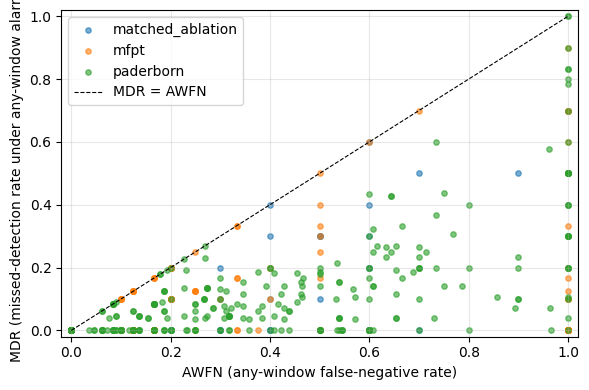

In [33]:
%cd /kaggle/working/project

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("output/all_metrics_combined.csv")
fig, ax = plt.subplots(figsize=(6, 4))
for src, sub in df.groupby("source"):
    ax.scatter(sub["awfn"], sub["mdr"], s=15, alpha=0.6, label=src)
ax.set_xlabel("AWFN (any-window false-negative rate)")
ax.set_ylabel("MDR (missed-detection rate under any-window alarm)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="MDR = AWFN")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("output/awfn_vs_mdr.png", dpi=300)
plt.savefig("output/awfn_vs_mdr.pdf")
print("Saved output/awfn_vs_mdr.png and .pdf")

In [40]:
%cd /kaggle/working

from IPython.display import FileLink, display
import os

zip_path = "all_outputs.zip"

if os.path.isfile(zip_path):
    display(FileLink(zip_path))
else:
    print("ZIP not found. Create it before downloading.")

/kaggle/working


/kaggle/working/all_outputs.zip